# OpenPowerlifting Data Analysis
## Competitive Powerlifting: Performance Insights and Trends

This analysis explores competitive powerlifting data to uncover insights about:
- Weight class distribution and performance
- Performance evolution over time (2009-2024)
- Success rates across different lifts
- Age-performance relationships
- Lift contributions to total performance
- Regional participation trends

## 1. Setup and Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style inspired by powerliftingindata.com
plt.style.use('seaborn-v0_8-whitegrid')
# Define custom color palette for lifts
LIFT_COLORS = {
    'squat': '#E63946',      # Red for Squat
    'bench': '#457B9D',      # Blue for Bench Press
    'deadlift': '#2A9D8F',   # Teal/Green for Deadlift
    'total': '#264653'       # Dark blue-grey for Total
}
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [63]:
# Load the dataset
print("Loading OpenPowerlifting dataset...")
df = pd.read_csv('../data/openpowerlifting.csv', low_memory=False)
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
print("\nColumn names:")
print(df.columns.tolist())

Loading OpenPowerlifting dataset...
Dataset loaded: 3,043,013 rows, 41 columns

Column names:
['Name', 'Sex', 'Event', 'Equipment', 'Age', 'AgeClass', 'BirthYearClass', 'Division', 'BodyweightKg', 'WeightClassKg', 'Squat1Kg', 'Squat2Kg', 'Squat3Kg', 'Squat4Kg', 'Best3SquatKg', 'Bench1Kg', 'Bench2Kg', 'Bench3Kg', 'Bench4Kg', 'Best3BenchKg', 'Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg', 'Deadlift4Kg', 'Best3DeadliftKg', 'TotalKg', 'Place', 'Dots', 'Wilks', 'Glossbrenner', 'Goodlift', 'Tested', 'Country', 'State', 'Federation', 'ParentFederation', 'Date', 'MeetCountry', 'MeetState', 'MeetTown', 'MeetName']


In [4]:
# Display first few rows and data types
print("First 5 rows:")
display(df.head())
print("\nData types:")
print(df.dtypes)
print("\nBasic info:")
print(df.info())

First 5 rows:


,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Tested,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName
0,Alona Vladi,F,SBD,Raw,33.0,24-34,24-39,O,58.30,60,...,Yes,Russia,NaN,GFP,NaN,2019-05-11,Russia,NaN,Bryansk,Open Tournament
1,Galina Solovyanova,F,SBD,Raw,43.0,40-44,40-49,M1,73.10,75,...,Yes,Russia,NaN,GFP,NaN,2019-05-11,Russia,NaN,Bryansk,Open Tournament
2,Daniil Voronin,M,SBD,Raw,15.5,16-17,14-18,T,67.40,75,...,Yes,Russia,NaN,GFP,NaN,2019-05-11,Russia,NaN,Bryansk,Open Tournament
3,Aleksey Krasov,M,SBD,Raw,35.0,35-39,24-39,O,66.65,75,...,Yes,Russia,NaN,GFP,NaN,2019-05-11,Russia,NaN,Bryansk,Open Tournament
4,Margarita Pleschenkova,M,SBD,Raw,26.5,24-34,24-39,O,72.45,75,...,Yes,Russia,NaN,GFP,NaN,2019-05-11,Russia,NaN,Bryansk,Open Tournament



Data types:
Name                 object
Sex                  object
Event                object
Equipment            object
Age                 float64
AgeClass             object
BirthYearClass       object
Division             object
BodyweightKg        float64
WeightClassKg        object
Squat1Kg            float64
Squat2Kg            float64
Squat3Kg            float64
Squat4Kg            float64
Best3SquatKg        float64
Bench1Kg            float64
Bench2Kg            float64
Bench3Kg            float64
Bench4Kg            float64
Best3BenchKg        float64
Deadlift1Kg         float64
Deadlift2Kg         float64
Deadlift3Kg         float64
Deadlift4Kg         float64
Best3DeadliftKg     float64
TotalKg             float64
Place                object
Dots                float64
Wilks               float64
Glossbrenner        float64
Goodlift            float64
Tested               object
Country              object
State                object
Federation           object
ParentF

## 2. Data Preprocessing

### 2.1 Filter for Full Power (SBD) Competitions

In [64]:
print(f"Original dataset size: {len(df):,} rows")

# Keep only full power competitions (SBD - Squat, Bench, Deadlift)
# Check if Event column exists and filter for SBD
if 'Event' in df.columns:
    df_full_power = df[df['Event'] == 'SBD'].copy()
    print(f"After filtering for full power (SBD): {len(df_full_power):,} rows")
else:
    # If no Event column, we need to ensure all three lifts are present
    df_full_power = df[
        df['Best3SquatKg'].notna() & 
        df['Best3BenchKg'].notna() & 
        df['Best3DeadliftKg'].notna()
    ].copy()
    print(f"After filtering for complete SBD data: {len(df_full_power):,} rows")

Original dataset size: 3,043,013 rows
After filtering for full power (SBD): 2,107,555 rows


### 2.2 Remove Missing Values

In [65]:
# Check for missing values in key columns
print("Missing values in key columns:")
key_columns = ['BodyweightKg', 'TotalKg', 'Sex', 'Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg']
print(df_full_power[key_columns].isnull().sum())

# Remove rows with missing bodyweight or total
df_clean = df_full_power.dropna(subset=['BodyweightKg', 'TotalKg']).copy()
print(f"\nAfter removing missing bodyweight/total: {len(df_clean):,} rows")

# Remove rows with missing Sex
df_clean = df_clean.dropna(subset=['Sex']).copy()
print(f"After removing missing sex: {len(df_clean):,} rows")

Missing values in key columns:
BodyweightKg        25993
TotalKg            154729
Sex                     0
Best3SquatKg        93515
Best3BenchKg       124733
Best3DeadliftKg    135745
dtype: int64

After removing missing bodyweight/total: 1,938,866 rows
After removing missing sex: 1,938,866 rows


### 2.3 Remove Outliers and Unrealistic Values

In [66]:
# Define thresholds for outlier removal
print("Removing outliers with the following criteria:")
print("- Bodyweight: 40kg - 200kg")
print("- Total: 100kg - 1500kg")
print("- Age: 10 - 100 years")
print("- Individual lifts: 20kg - 600kg")

# Remove unrealistic bodyweights
df_clean = df_clean[(df_clean['BodyweightKg'] >= 40) & (df_clean['BodyweightKg'] <= 200)].copy()

# Remove unrealistic totals
df_clean = df_clean[(df_clean['TotalKg'] >= 100) & (df_clean['TotalKg'] <= 1500)].copy()

# Remove unrealistic ages if Age column exists
if 'Age' in df_clean.columns:
    df_clean = df_clean[
        (df_clean['Age'].isna()) | 
        ((df_clean['Age'] >= 10) & (df_clean['Age'] <= 100))
    ].copy()

# Remove unrealistic individual lifts
for lift in ['Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg']:
    if lift in df_clean.columns:
        df_clean = df_clean[
            (df_clean[lift].isna()) | 
            ((df_clean[lift] >= 20) & (df_clean[lift] <= 600))
        ].copy()

print(f"\nFinal cleaned dataset: {len(df_clean):,} rows")
print(f"Removed {len(df) - len(df_clean):,} rows ({(len(df) - len(df_clean))/len(df)*100:.1f}%)")

Removing outliers with the following criteria:
- Bodyweight: 40kg - 200kg
- Total: 100kg - 1500kg
- Age: 10 - 100 years
- Individual lifts: 20kg - 600kg

Final cleaned dataset: 1,934,055 rows
Removed 1,108,958 rows (36.4%)


### 2.4 Add Weight Classes

Create real competitive weight classes for men and women based on IPF standards.

In [67]:
def assign_weight_class(row):
    """Assign IPF weight classes based on sex and bodyweight"""
    bw = row['BodyweightKg']
    sex = row['Sex']
    
    if sex == 'M':
        if bw <= 59:
            return '59kg'
        elif bw <= 66:
            return '66kg'
        elif bw <= 74:
            return '74kg'
        elif bw <= 83:
            return '83kg'
        elif bw <= 93:
            return '93kg'
        elif bw <= 105:
            return '105kg'
        elif bw <= 120:
            return '120kg'
        else:
            return '120kg+'
    elif sex == 'F':
        if bw <= 47:
            return '47kg'
        elif bw <= 52:
            return '52kg'
        elif bw <= 57:
            return '57kg'
        elif bw <= 63:
            return '63kg'
        elif bw <= 69:
            return '69kg'
        elif bw <= 76:
            return '76kg'
        elif bw <= 84:
            return '84kg'
        else:
            return '84kg+'
    else:
        return 'Unknown'

df_clean['WeightClass'] = df_clean.apply(assign_weight_class, axis=1)
print("Weight classes assigned successfully!")
print("\nWeight class distribution:")
print(df_clean.groupby(['Sex', 'WeightClass']).size())

Weight classes assigned successfully!

Weight class distribution:
Sex  WeightClass
F    47kg            27262
     52kg            58127
     57kg            68924
     63kg            89606
     69kg            78585
     76kg            76427
     84kg            54346
     84kg+           78398
M    105kg          221312
     120kg          162531
     120kg+         120346
     59kg            93534
     66kg            97948
     74kg           179300
     83kg           283305
     93kg           244046
Mx   Unknown            58
dtype: int64


### 2.5 Parse and Filter Dates (2009-2024)

In [68]:
# Parse date column
if 'Date' in df_clean.columns:
    df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce')
    df_clean['Year'] = df_clean['Date'].dt.year
    
    # Filter for 2009-2024
    df_clean = df_clean[
        (df_clean['Year'].notna()) & 
        (df_clean['Year'] >= 2005) & 
        (df_clean['Year'] <= 2023)
    ].copy()
    
    print(f"Dataset filtered to 2009-2024: {len(df_clean):,} rows")
    print("\nCompetitions per year:")
    print(df_clean['Year'].value_counts().sort_index())
else:
    print("Warning: No Date column found in dataset")

Dataset filtered to 2009-2024: 1,640,939 rows

Competitions per year:
Year
2005     17192
2006     16735
2007     18694
2008     19915
2009     20322
2010     46867
2011     51636
2012     57242
2013     65916
2014     96943
2015    118203
2016    135527
2017    147199
2018    157680
2019    167297
2020     97790
2021    122881
2022    150009
2023    132891
Name: count, dtype: int64


## 3. Exploratory Statistical Analysis

In [10]:
print("=" * 80)
print("EXPLORATORY STATISTICAL ANALYSIS")
print("=" * 80)

print(f"\nTotal number of competition entries: {len(df_clean):,}")
print(f"\nSex distribution:")
print(df_clean['Sex'].value_counts())
print(f"\nPercentage: {df_clean['Sex'].value_counts(normalize=True) * 100}")

EXPLORATORY STATISTICAL ANALYSIS

Total number of competition entries: 1,640,955

Sex distribution:
Sex
M     1152029
F      488868
Mx         58
Name: count, dtype: int64

Percentage: Sex
M     70.204789
F     29.791676
Mx     0.003535
Name: proportion, dtype: float64


In [27]:
# Overall statistics by sex
print("\n" + "=" * 80)
print("OVERALL STATISTICS BY SEX")
print("=" * 80)

for sex in ['M', 'F']:
    data = df_clean[df_clean['Sex'] == sex]
    print(f"\n{'MEN' if sex == 'M' else 'WOMEN'}:")
    print(f"  Count: {len(data):,}")
    print(f"  Bodyweight - Mean: {data['BodyweightKg'].mean():.1f}kg, Median: {data['BodyweightKg'].median():.1f}kg")
    print(f"  Total - Mean: {data['TotalKg'].mean():.1f}kg, Median: {data['TotalKg'].median():.1f}kg")
    print(f"  Squat - Mean: {data['Best3SquatKg'].mean():.1f}kg, Median: {data['Best3SquatKg'].median():.1f}kg")
    print(f"  Bench - Mean: {data['Best3BenchKg'].mean():.1f}kg, Median: {data['Best3BenchKg'].median():.1f}kg")
    print(f"  Deadlift - Mean: {data['Best3DeadliftKg'].mean():.1f}kg, Median: {data['Best3DeadliftKg'].median():.1f}kg")
    
    if 'Age' in data.columns:
        age_data = data['Age'].dropna()
        if len(age_data) > 0:
            print(f"  Age - Mean: {age_data.mean():.1f}, Median: {age_data.median():.1f}")


OVERALL STATISTICS BY SEX

MEN:
  Count: 1,152,016
  Bodyweight - Mean: 89.1kg, Median: 87.5kg
  Total - Mean: 532.0kg, Median: 525.0kg
  Squat - Mean: 194.9kg, Median: 190.0kg
  Bench - Mean: 127.2kg, Median: 122.5kg
  Deadlift - Mean: 210.0kg, Median: 210.0kg
  Age - Mean: 28.3, Median: 24.5

WOMEN:
  Count: 488,865
  Bodyweight - Mean: 69.0kg, Median: 65.7kg
  Total - Mean: 303.8kg, Median: 297.1kg
  Squat - Mean: 113.8kg, Median: 110.0kg
  Bench - Mean: 61.9kg, Median: 59.0kg
  Deadlift - Mean: 128.2kg, Median: 126.0kg
  Age - Mean: 29.2, Median: 26.0


In [12]:
# Distribution statistics
print("\n" + "=" * 80)
print("DISTRIBUTION STATISTICS")
print("=" * 80)

print("\nTotal Performance Distribution (all athletes):")
print(df_clean['TotalKg'].describe())

print("\nBodyweight Distribution:")
print(df_clean['BodyweightKg'].describe())


DISTRIBUTION STATISTICS

Total Performance Distribution (all athletes):
count    1.640955e+06
mean     4.640206e+02
std      1.661631e+02
min      1.000000e+02
25%      3.300000e+02
50%      4.558600e+02
75%      5.783300e+02
max      1.407500e+03
Name: TotalKg, dtype: float64

Bodyweight Distribution:
count    1.640955e+06
mean     8.310253e+01
std      2.248163e+01
min      4.000000e+01
25%      6.613000e+01
50%      8.100000e+01
75%      9.730000e+01
max      2.000000e+02
Name: BodyweightKg, dtype: float64


TOTAL KG DISTRIBUTION BY SEX - GENERAL ANALYSIS


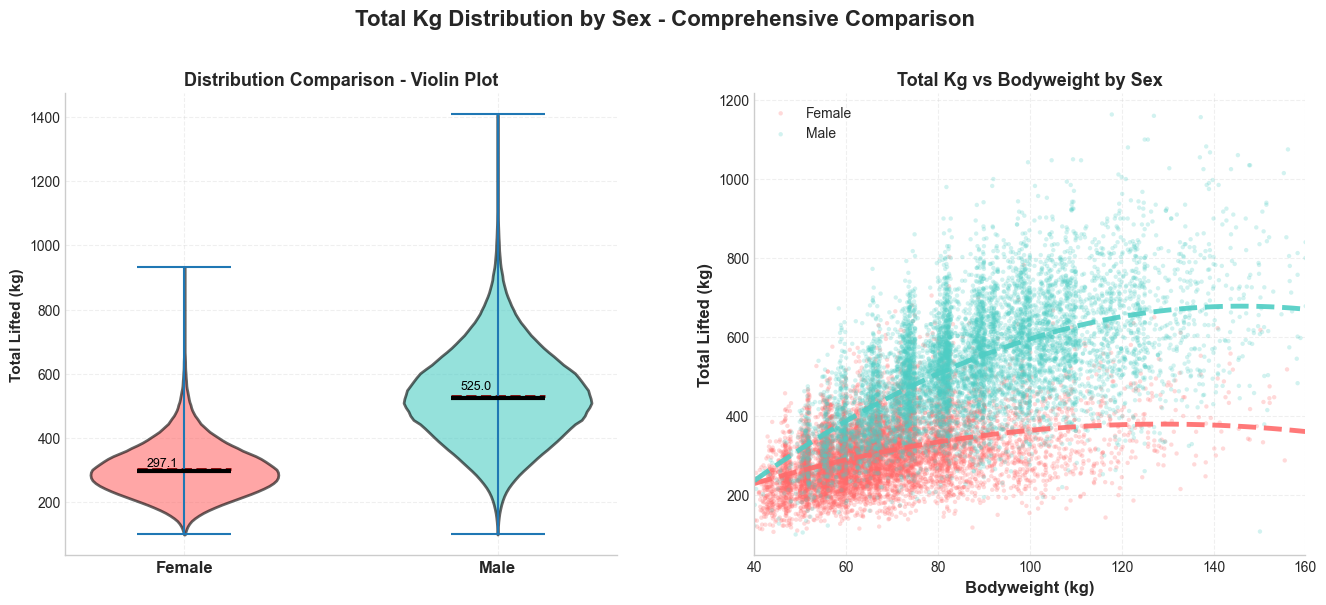

In [79]:
print("=" * 80)
print("TOTAL KG DISTRIBUTION BY SEX - GENERAL ANALYSIS")
print("=" * 80)

# Prepare data
df_general = df_clean.copy()

# Create visualization with only violin and scatter
fig = plt.figure(figsize=(16, 6))
gs = fig.add_gridspec(1, 2, hspace=0.3, wspace=0.25)

colors_sex = {'F': '#FF6B6B', 'M': '#4ECDC4'}

# ===== 1. VIOLIN PLOT =====
ax1 = fig.add_subplot(gs[0, 0])

violin_data = [df_general[df_general['Sex'] == 'F']['TotalKg'],
               df_general[df_general['Sex'] == 'M']['TotalKg']]

violin_parts = ax1.violinplot(violin_data, positions=[1, 2], 
                               showmeans=True, showmedians=True, 
                               widths=0.6)

for i, pc in enumerate(violin_parts['bodies']):
    sex = ['F', 'M'][i]
    pc.set_facecolor(colors_sex[sex])
    pc.set_alpha(0.6)
    pc.set_edgecolor('black')
    pc.set_linewidth(2)

violin_parts['cmedians'].set_edgecolor('black')
violin_parts['cmedians'].set_linewidth(3)
violin_parts['cmeans'].set_edgecolor('darkred')
violin_parts['cmeans'].set_linewidth(2)
violin_parts['cmeans'].set_linestyle('--')

ax1.set_xticks([1, 2])
ax1.set_xticklabels(['Female', 'Male'], fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Lifted (kg)', fontsize=11, fontweight='bold')
ax1.set_title('Distribution Comparison - Violin Plot', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Add statistics at top of violin (no box)
for i, sex in enumerate(['F', 'M'], 1):
    data = df_general[df_general['Sex'] == sex]['TotalKg']
    median = data.median()
    max_val = ax1.get_ylim()[1]
    ax1.text(i - 0.07, median * 1.05, f'{median:.1f}', 
            ha='center', fontsize=9, 
            color='black')

# ===== 2. SCATTER: TOTAL KG vs BODYWEIGHT =====
ax2 = fig.add_subplot(gs[0, 1])

# Sample for visualization
sample_size = 8000
for sex, label in [('F', 'Female'), ('M', 'Male')]:
    data_sex = df_general[df_general['Sex'] == sex]
    if len(data_sex) > sample_size:
        data_sample = data_sex.sample(n=sample_size, random_state=42)
    else:
        data_sample = data_sex
    
    ax2.scatter(data_sample['BodyweightKg'], data_sample['TotalKg'], 
               alpha=0.25, s=10, color=colors_sex[sex], label=label, edgecolors='none')
    
    # Trend line
    valid_data = data_sample[['BodyweightKg', 'TotalKg']].dropna()
    z = np.polyfit(valid_data['BodyweightKg'], valid_data['TotalKg'], 2)
    p = np.poly1d(z)
    x_trend = np.linspace(valid_data['BodyweightKg'].min(), 
                         valid_data['BodyweightKg'].max(), 100)
    ax2.plot(x_trend, p(x_trend), color=colors_sex[sex], linewidth=3.5, 
            linestyle='--', alpha=0.9)

ax2.set_xlabel('Bodyweight (kg)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Lifted (kg)', fontsize=12, fontweight='bold')
ax2.set_title('Total Kg vs Bodyweight by Sex', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='upper left')
ax2.grid(alpha=0.3, linestyle='--')
ax2.set_xlim(40, 160)

plt.suptitle('Total Kg Distribution by Sex - Comprehensive Comparison', 
            fontsize=16, fontweight='bold', y=1.02)

plt.show()

## Visualization 1: Gender Composition Over Time

**Analysis:** How has the gender distribution in competitive powerlifting evolved over time in IPF Raw competitions?

Global dataset entries: 1,640,939
Italia dataset entries: 5,577


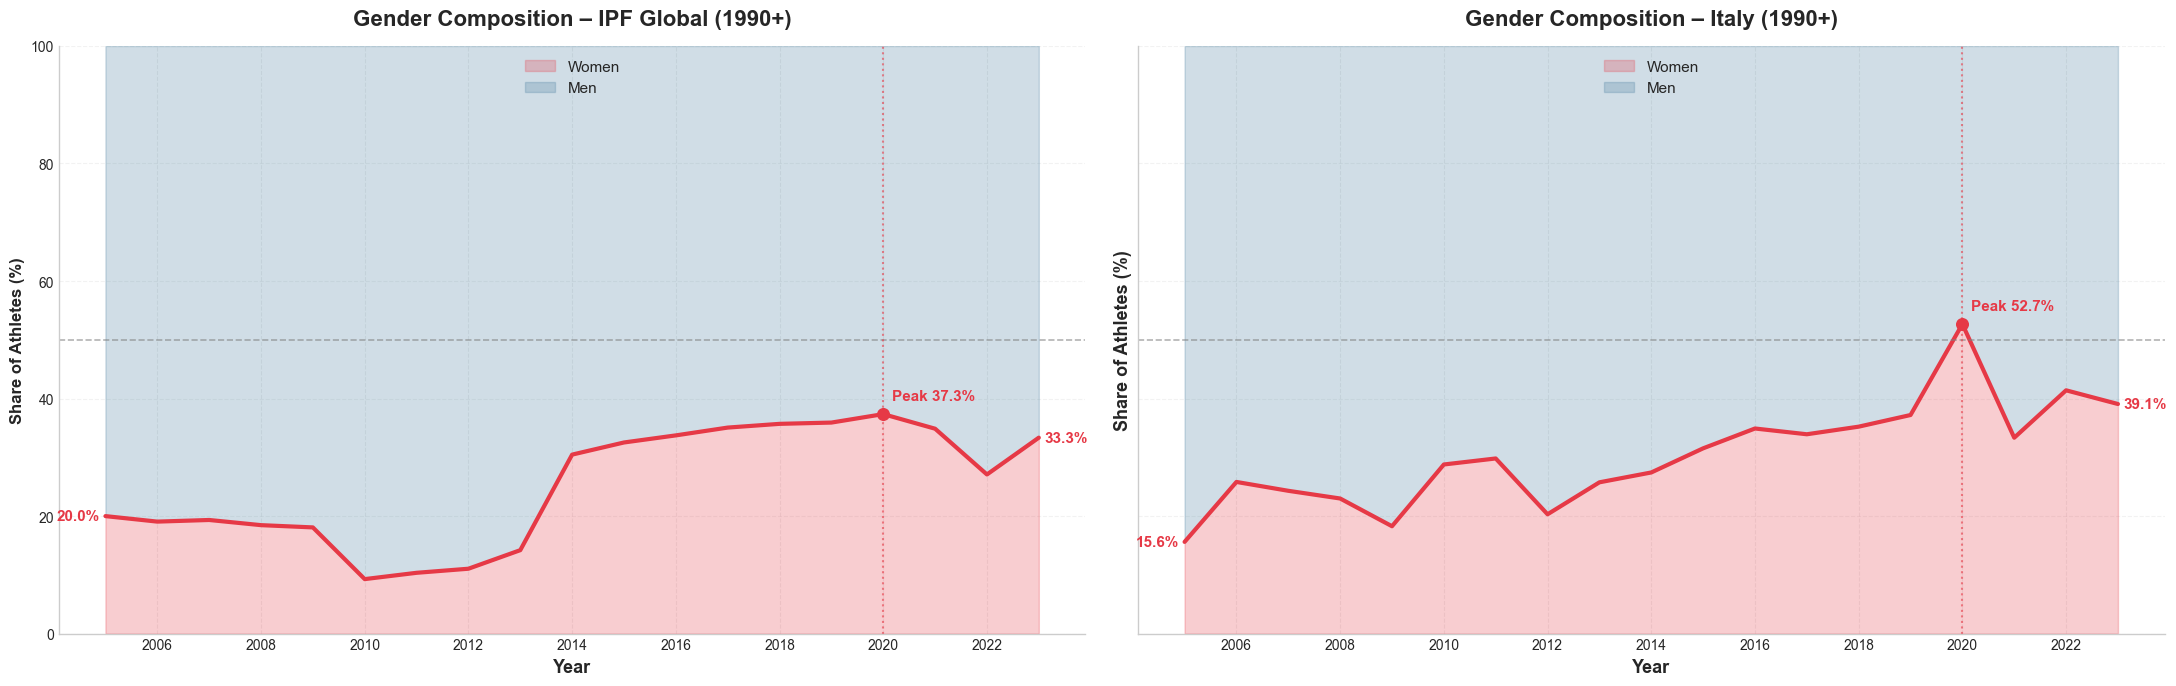

In [80]:
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================
# Funzione per grafico Gender Composition
# ============================
def plot_gender_composition(ax, df, title_suffix):
    # Aggrega per anno e sesso
    yearly_gender = df.groupby(['Year','Sex']).agg(entries=('Name','count')).reset_index()
    
    pivot = yearly_gender.pivot(index='Year', columns='Sex', values='entries').fillna(0)
    
    # Assicura che ci siano entrambe le colonne
    if 'F' not in pivot.columns:
        pivot['F'] = 0
    if 'M' not in pivot.columns:
        pivot['M'] = 0

    pivot['total'] = pivot['F'] + pivot['M']
    pivot['pct_F'] = np.where(pivot['total']>0, pivot['F'] / pivot['total'] * 100, 0)
    pivot['pct_M'] = 100 - pivot['pct_F']

    # ============================
    # Aree
    # ============================
    ax.fill_between(pivot.index, 0, pivot['pct_F'], color='#E63946', alpha=0.25, label='Women')
    ax.fill_between(pivot.index, pivot['pct_F'], 100, color='#457B9D', alpha=0.25, label='Men')
    ax.plot(pivot.index, pivot['pct_F'], color='#E63946', linewidth=3)

    # Linea 50% riferimento
    ax.axhline(50, color='gray', linestyle='--', linewidth=1.2, alpha=0.6)

    # ============================
    # Peak year donne
    # ============================
    pct_f = pivot['pct_F'].dropna()
    if not pct_f.empty and pct_f.sum() > 0:
        peak_year = pct_f.idxmax()
        peak_value = pct_f.loc[peak_year]
        ax.scatter(peak_year, peak_value, color='#E63946', s=70, zorder=5)
        ax.axvline(peak_year, color='#E63946', linestyle=':', linewidth=1.5, alpha=0.6)
        ax.annotate(
            f'Peak {peak_value:.1f}%',
            xy=(peak_year, peak_value),
            xytext=(6,10),
            textcoords='offset points',
            fontsize=11,
            fontweight='600',
            color='#E63946'
        )
    else:
        peak_year = None
        peak_value = None
        ax.text(0.5,0.88,'No female participation', transform=ax.transAxes,
                ha='center', fontsize=11, color='gray', alpha=0.6)

    # ============================
    # Percentuali inizio/fine (fuori grafico)
    # ============================
    start_year = pivot.index.min()
    end_year = pivot.index.max()
    start_pct = pivot.loc[start_year,'pct_F'] if start_year in pivot.index else 0
    end_pct = pivot.loc[end_year,'pct_F'] if end_year in pivot.index else 0

    ax.text(0.04, start_pct/100, f'{start_pct:.1f}%', transform=ax.transAxes,
            fontsize=11, fontweight='600', color='#E63946', ha='right', va='center', clip_on=False)
    ax.text(0.96, end_pct/100, f'{end_pct:.1f}%', transform=ax.transAxes,
            fontsize=11, fontweight='600', color='#E63946', ha='left', va='center', clip_on=False)

    # ============================
    # Formattazione assi
    # ============================
    ax.set_ylim(0,100)
    ax.set_ylabel('Share of Athletes (%)', fontsize=13, fontweight='600')
    ax.set_xlabel('Year', fontsize=13, fontweight='600')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(title_suffix, fontsize=16, fontweight='700', pad=15)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
    ax.legend(framealpha=0.95, fontsize=11, loc='upper center')


# ============================
# Prepara dataset globale e Italia
# ============================
required_cols = {'Sex','Year','Name'}
for col in required_cols:
    if col not in df_clean.columns:
        raise ValueError(f"Missing required column: {col}")

# Globale
df_gender = df_clean[df_clean['Year']>=1990].copy()

# Italia
if 'Country' in df_gender.columns:
    df_italy = df_gender[df_gender['Country']=='Italy'].copy()
else:
    df_italy = pd.DataFrame(columns=df_gender.columns)

print(f"Global dataset entries: {len(df_gender):,}")
print(f"Italia dataset entries: {len(df_italy):,}")

# ============================
# Grafico comparativo
# ============================
fig, axes = plt.subplots(1,2, figsize=(22,7), sharey=True)

plot_gender_composition(axes[0], df_gender, 'Gender Composition – IPF Global (1990+)')
plot_gender_composition(axes[1], df_italy, 'Gender Composition – Italy (1990+)')

axes[0].set_ylabel('Share of Athletes (%)', fontsize=12, fontweight='600')
axes[0].legend(framealpha=0.95, fontsize=11, loc='upper center')

plt.tight_layout()
plt.show()




## Visualization 3: Weight Class Distribution

**Analysis:** How do weight class distributions differ between men and women? Should women have additional upper weight classes?

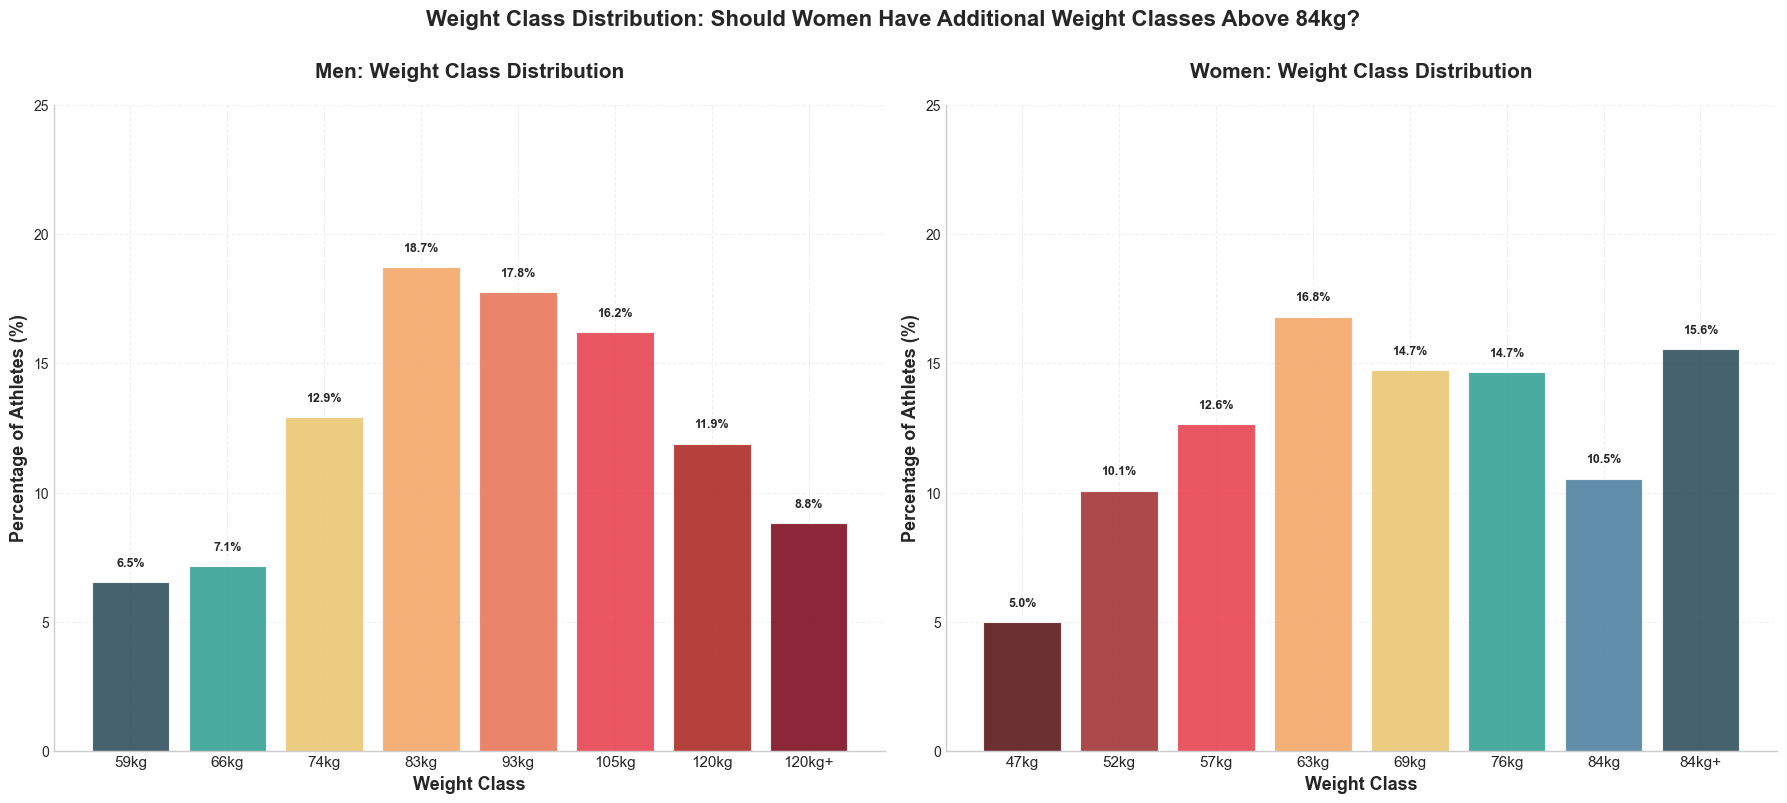

Men have 8 weight classes (including 120kg+)
Women have 8 weight classes (max 84kg+)
Women in 84kg+ class: 76,051 (15.6%)
Men in 120kg+ class: 101,619 (8.8%)
⚠ The 84kg+ class for women contains 15.6% of all female athletes!
This suggests the need for additional upper weight classes for women.


In [82]:
# Comparative Weight Class Distribution: Men vs Women
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

men_data = df_clean[df_clean['Sex'] == 'M']
women_data = df_clean[df_clean['Sex'] == 'F']

weight_class_order_m = ['59kg', '66kg', '74kg', '83kg', '93kg', '105kg', '120kg', '120kg+']
weight_class_order_f = ['47kg', '52kg', '57kg', '63kg', '69kg', '76kg', '84kg', '84kg+']

# Men's distribution
ax1 = axes[0]
wc_counts_m = men_data['WeightClass'].value_counts().reindex(weight_class_order_m, fill_value=0)
wc_pct_m = (wc_counts_m / wc_counts_m.sum() * 100)

colors_m = ['#264653', '#2a9d8f', '#e9c46a', '#f4a261', '#e76f51', '#e63946', '#a8201a', '#780116']
bars_m = ax1.bar(range(len(wc_counts_m)), wc_pct_m.values, color=colors_m, 
                 edgecolor='white', linewidth=0.8, alpha=0.85)

ax1.set_xticks(range(len(wc_counts_m)))
ax1.set_xticklabels(wc_counts_m.index, rotation=0, fontsize=11)
ax1.set_ylabel('Percentage of Athletes (%)', fontsize=13, fontweight='600')
ax1.set_xlabel('Weight Class', fontsize=13, fontweight='600')
ax1.set_title('Men: Weight Class Distribution', fontsize=15, fontweight='700', pad=20)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
ax1.set_ylim(0, max(wc_pct_m.max(), 25))

# Add percentage labels
for i, v in enumerate(wc_pct_m.values):
    ax1.text(i, v + 0.5, f'{v:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='600')

# Women's distribution
ax2 = axes[1]
wc_counts_f = women_data['WeightClass'].value_counts().reindex(weight_class_order_f, fill_value=0)
wc_pct_f = (wc_counts_f / wc_counts_f.sum() * 100)

colors_f = ['#540b0e', '#9e2a2b', '#e63946', '#f4a261', '#e9c46a', '#2a9d8f', '#457b9d', '#264653']
bars_f = ax2.bar(range(len(wc_counts_f)), wc_pct_f.values, color=colors_f, 
                 edgecolor='white', linewidth=0.8, alpha=0.85)

ax2.set_xticks(range(len(wc_counts_f)))
ax2.set_xticklabels(wc_counts_f.index, rotation=0, fontsize=11)
ax2.set_ylabel('Percentage of Athletes (%)', fontsize=13, fontweight='600')
ax2.set_xlabel('Weight Class', fontsize=13, fontweight='600')
ax2.set_title('Women: Weight Class Distribution', fontsize=15, fontweight='700', pad=20)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
ax2.set_ylim(0, max(wc_pct_m.max(), 25))

# Add percentage labels
for i, v in enumerate(wc_pct_f.values):
    ax2.text(i, v + 0.5, f'{v:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='600')


plt.suptitle('Weight Class Distribution: Should Women Have Additional Weight Classes Above 84kg?',
             fontsize=16, fontweight='700', y=1.00)
plt.tight_layout()
plt.savefig('../viz/viz3_weight_class_comparison.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Men have {len(weight_class_order_m)} weight classes (including 120kg+)")
print(f"Women have {len(weight_class_order_f)} weight classes (max 84kg+)")
print(f"Women in 84kg+ class: {wc_counts_f.values[7]:,} ({wc_pct_f.values[7]:.1f}%)")
print(f"Men in 120kg+ class: {wc_counts_m.values[7]:,} ({wc_pct_m.values[7]:.1f}%)")
print(f"⚠ The 84kg+ class for women contains {wc_pct_f.values[7]:.1f}% of all female athletes!")
print(f"This suggests the need for additional upper weight classes for women.")

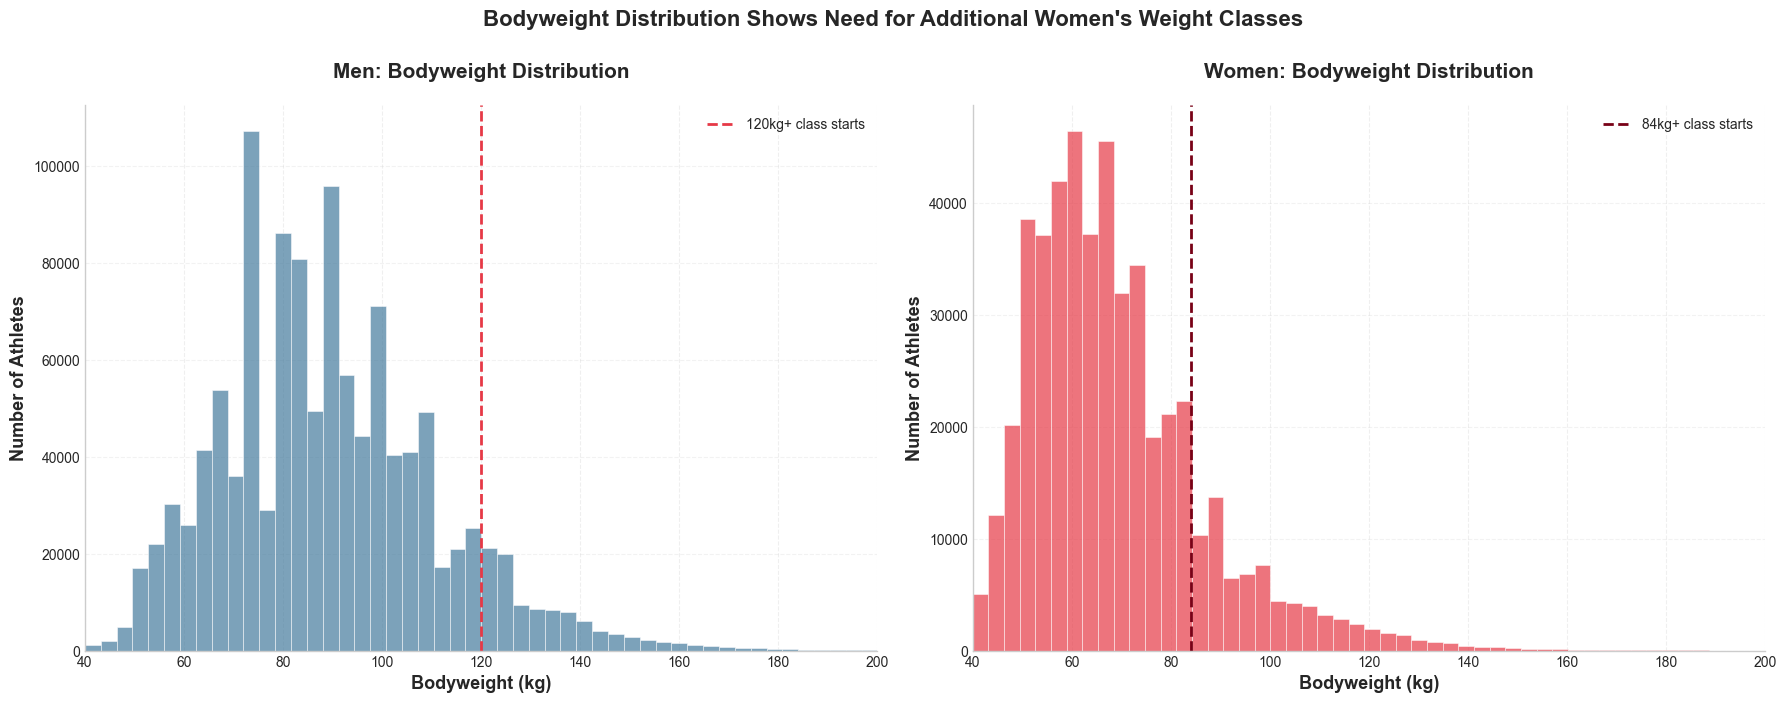

In [83]:
# Bodyweight Distribution: Evidence for More Women's Weight Classes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Men's bodyweight distribution
men_bw = men_data['BodyweightKg'].dropna()
ax1.hist(men_bw, bins=50, color='#457B9D', alpha=0.7, edgecolor='white', linewidth=0.5)
ax1.axvline(120, color='#E63946', linestyle='--', linewidth=2, label='120kg+ class starts')
ax1.set_xlabel('Bodyweight (kg)', fontsize=13, fontweight='600')
ax1.set_ylabel('Number of Athletes', fontsize=13, fontweight='600')
ax1.set_title('Men: Bodyweight Distribution', fontsize=15, fontweight='700', pad=20)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
ax1.legend(fontsize=10)
ax1.set_xlim(40, 200)

# Women's bodyweight distribution
women_bw = women_data['BodyweightKg'].dropna()
ax2.hist(women_bw, bins=50, color='#E63946', alpha=0.7, edgecolor='white', linewidth=0.5)
ax2.axvline(84, color='#780116', linestyle='--', linewidth=2, label='84kg+ class starts')
ax2.set_xlabel('Bodyweight (kg)', fontsize=13, fontweight='600')
ax2.set_ylabel('Number of Athletes', fontsize=13, fontweight='600')
ax2.set_title('Women: Bodyweight Distribution', fontsize=15, fontweight='700', pad=20)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
ax2.legend(fontsize=10)
ax2.set_xlim(40, 200)

# Count athletes above the + class
men_over_120 = (men_bw > 120).sum()
women_over_84 = (women_bw > 84).sum()
women_over_100 = (women_bw > 100).sum()
women_over_120 = (women_bw > 120).sum()

plt.suptitle("Bodyweight Distribution Shows Need for Additional Women's Weight Classes",
             fontsize=16, fontweight='700', y=1.00)
plt.tight_layout()
plt.savefig('../viz/viz3_bodyweight_distribution.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

**Analysis:** How has competitive performance evolved over the last decade in IPF-affiliated Raw competitions?

NameError: name 'men_perf_time' is not defined

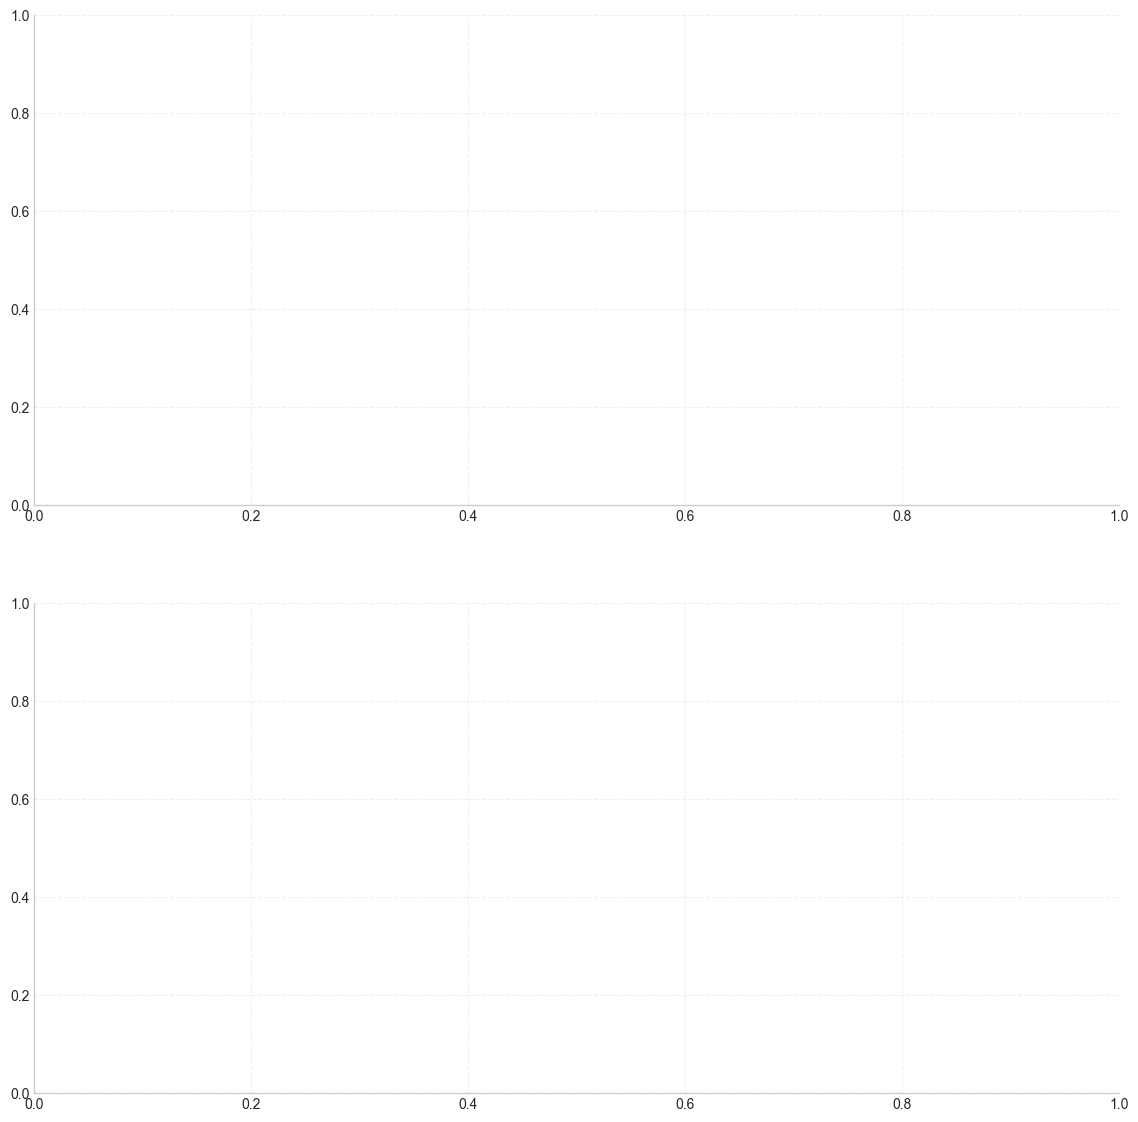

In [86]:
# Highest Total and Median Per Year - Men (IPF 2010-2023)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 14))

weight_class_order_m = ['59kg', '66kg', '74kg', '83kg', '93kg', '105kg', '120kg', '120kg+']
colors_m = ['#003f5c', '#2f4b7c', '#665191', '#a05195', '#d45087', '#f95d6a', '#ff7c43', '#ffa600']

# Top subplot: Highest totals
for idx, wc in enumerate(weight_class_order_m):
    wc_data = men_perf_time[men_perf_time['WeightClass'] == wc]
    yearly_max = wc_data.groupby('Year')['TotalKg'].max()
    if len(yearly_max) > 0:
        ax1.plot(yearly_max.index, yearly_max.values, marker='o', linewidth=2.5, label=wc, color=colors_m[idx], markersize=6, alpha=0.9)

ax1.set_ylabel('Highest Total (kg)', fontsize=13, fontweight='600')
ax1.set_title('Highest Total Per Year Per Weight Class - Men (IPF 2010-2023) Raw, SBD, IPF-Affiliated Meets', fontsize=14, fontweight='700', pad=15)
ax1.legend(title='Weight Class', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.95, title_fontsize=10, fontsize=9)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.25, linestyle='--', linewidth=0.8)
ax1.set_xticks(range(2010, 2024))
ax1.set_xticklabels([])

# Bottom subplot: Median totals
for idx, wc in enumerate(weight_class_order_m):
    wc_data = men_perf_time[men_perf_time['WeightClass'] == wc]
    yearly_median = wc_data.groupby('Year')['TotalKg'].median()
    if len(yearly_median) > 0:
        ax2.plot(yearly_median.index, yearly_median.values, marker='s', linewidth=2.5, label=wc, color=colors_m[idx], markersize=6, alpha=0.9)

ax2.set_xlabel('Year', fontsize=13, fontweight='600')
ax2.set_ylabel('Median Total (kg)', fontsize=13, fontweight='600')
ax2.set_title('Median Total Per Year Per Weight Class - Men (IPF 2010-2023) Raw, SBD, IPF-Affiliated Meets', fontsize=14, fontweight='700', pad=15)
ax2.legend(title='Weight Class', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.95, title_fontsize=10, fontsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.25, linestyle='--', linewidth=0.8)
ax2.set_xticks(range(2010, 2024))
ax2.set_xticklabels(range(2010, 2024), rotation=45)

plt.tight_layout()
plt.savefig('viz/viz4_men_performance_over_time.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Men chart saved!")

In [ ]:
# Highest Total and Median Per Year - Women (IPF 2010-2023)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 14))

weight_class_order_f = ['47kg', '52kg', '57kg', '63kg', '69kg', '76kg', '84kg', '84kg+']
colors_f = ['#7400b8', '#6930c3', '#5e60ce', '#5390d9', '#4ea8de', '#48bfe3', '#56cfe1', '#64dfdf']

# Top subplot: Highest totals
for idx, wc in enumerate(weight_class_order_f):
    wc_data = women_perf_time[women_perf_time['WeightClass'] == wc]
    yearly_max = wc_data.groupby('Year')['TotalKg'].max()
    if len(yearly_max) > 0:
        ax1.plot(yearly_max.index, yearly_max.values, marker='o', linewidth=2.5, label=wc, color=colors_f[idx], markersize=6, alpha=0.9)

ax1.set_ylabel('Highest Total (kg)', fontsize=13, fontweight='600')
ax1.set_title('Highest Total Per Year Per Weight Class - Women (IPF 2010-2023) Raw, SBD, IPF-Affiliated Meets', fontsize=14, fontweight='700', pad=15)
ax1.legend(title='Weight Class', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.95, title_fontsize=10, fontsize=9)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.25, linestyle='--', linewidth=0.8)
ax1.set_xticks(range(2010, 2024))
ax1.set_xticklabels([])

# Bottom subplot: Median totals
for idx, wc in enumerate(weight_class_order_f):
    wc_data = women_perf_time[women_perf_time['WeightClass'] == wc]
    yearly_median = wc_data.groupby('Year')['TotalKg'].median()
    if len(yearly_median) > 0:
        ax2.plot(yearly_median.index, yearly_median.values, marker='s', linewidth=2.5, label=wc, color=colors_f[idx], markersize=6, alpha=0.9)

ax2.set_xlabel('Year', fontsize=13, fontweight='600')
ax2.set_ylabel('Median Total (kg)', fontsize=13, fontweight='600')
ax2.set_title('Median Total Per Year Per Weight Class - Women (IPF 2010-2023) Raw, SBD, IPF-Affiliated Meets', fontsize=14, fontweight='700', pad=15)
ax2.legend(title='Weight Class', bbox_to_anchor=(1.05, 1), loc='upper left', framealpha=0.95, title_fontsize=10, fontsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.25, linestyle='--', linewidth=0.8)
ax2.set_xticks(range(2010, 2024))
ax2.set_xticklabels(range(2010, 2024), rotation=45)

plt.tight_layout()
plt.savefig('viz/viz4_women_performance_over_time.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print("Women chart saved!")

**Analysis:** At what age are powerlifters most competitive? When do athletes peak?

AGE-PERFORMANCE ANALYSIS - IPF ATHLETES ONLY
Filters: Raw, IPF affiliates, 2010-2023
Athletes with age data: 223,792


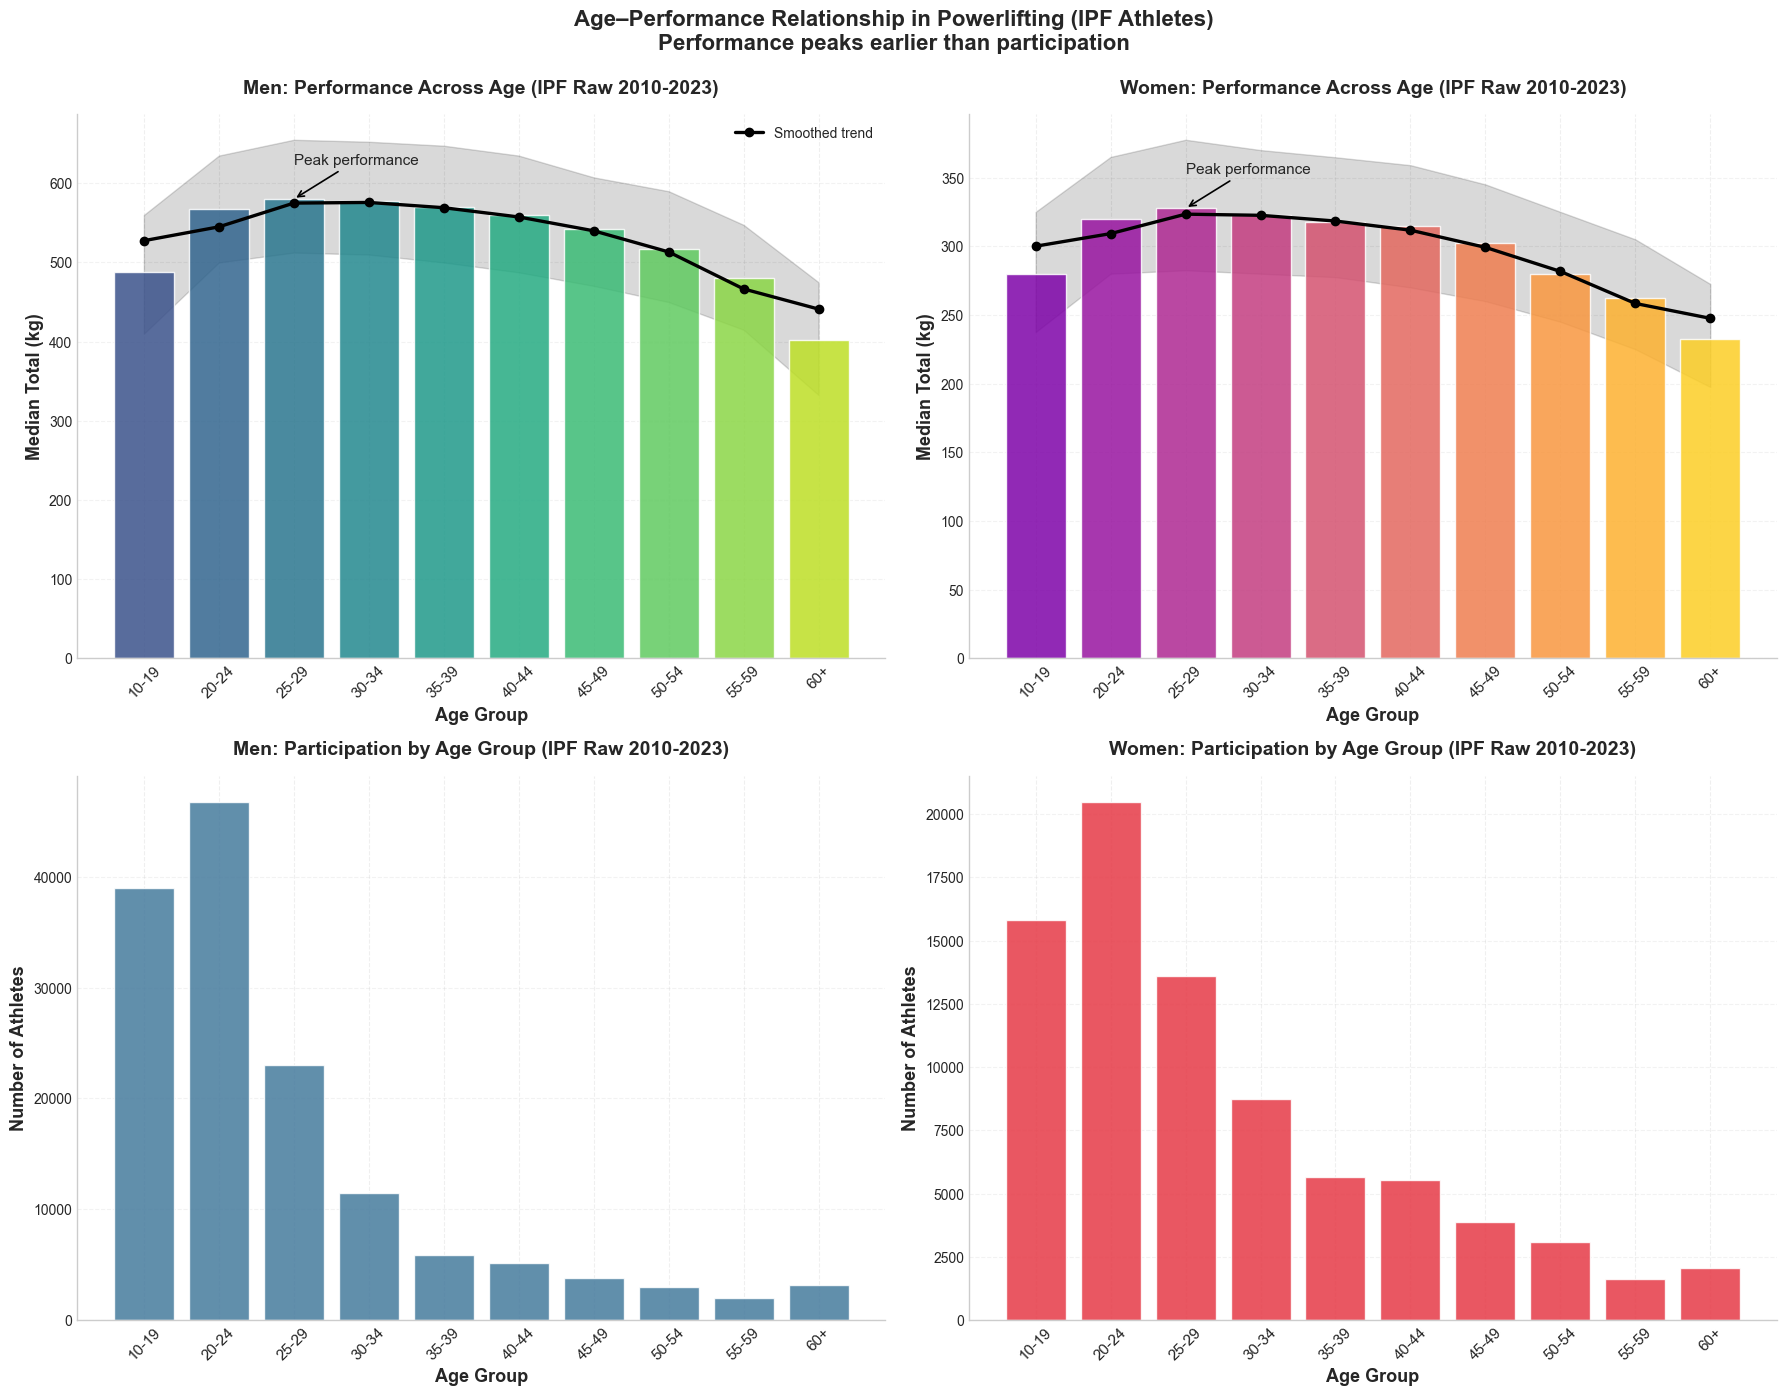

Age–performance visualization saved!


In [85]:
# ============================
# Age–Performance Analysis (IPF Athletes Only)
# ============================
# Using same filters as Performance Over Time visualization:
# - Raw equipment only
# - IPF and affiliate federations
# - Years 2010-2023

if 'Age' in df_clean.columns:

    # Apply IPF filters (same as visualization 2)
    df_age_ipf = df_clean.copy()

    # Filter 1: Raw equipment only
    if 'Equipment' in df_age_ipf.columns:
        df_age_ipf = df_age_ipf[df_age_ipf['Equipment'] == 'Raw'].copy()

    # Filter 2: IPF and affiliates
    if 'Federation' in df_age_ipf.columns:
        ipf_federations = ['IPF', 'USAPL', 'CPU', 'BP', 'EPA', 'IrishPF', 'PA', 'CAPO']
        df_age_ipf = df_age_ipf[df_age_ipf['Federation'].isin(ipf_federations)].copy()

    # Filter 3: Years 2010-2023
    if 'Year' in df_age_ipf.columns:
        df_age_ipf = df_age_ipf[(df_age_ipf['Year'] >= 2010) & (df_age_ipf['Year'] <= 2023)].copy()

    df_age = df_age_ipf[df_age_ipf['Age'].notna()].copy()

    print("=" * 80)
    print("AGE-PERFORMANCE ANALYSIS - IPF ATHLETES ONLY")
    print("Filters: Raw, IPF affiliates, 2010-2023")
    print(f"Athletes with age data: {len(df_age):,}")
    print("=" * 80)

    # --- Age bins ---
    age_bins = [10, 20, 25, 30, 35, 40, 45, 50, 55, 60, 100]
    age_labels = [
        '10-19', '20-24', '25-29', '30-34', '35-39',
        '40-44', '45-49', '50-54', '55-59', '60+'
    ]

    df_age['AgeGroup'] = pd.cut(
        df_age['Age'],
        bins=age_bins,
        labels=age_labels,
        right=False
    )

    fig, axes = plt.subplots(2, 2, figsize=(18, 14))

    # ============================
    # MEN
    # ============================
    men_age = df_age[df_age['Sex'] == 'M']

    age_perf_m = men_age.groupby('AgeGroup')['TotalKg'].agg(
        median='median',
        p25=lambda x: np.percentile(x, 25),
        p75=lambda x: np.percentile(x, 75),
        count='count'
    ).dropna()

    # --- Normalize to peak ---
    peak_median_m = age_perf_m['median'].max()
    age_perf_m['rel_to_peak'] = age_perf_m['median'] / peak_median_m * 100

    # --- Smoothed trend ---
    age_perf_m['smooth'] = age_perf_m['median'].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    x_m = range(len(age_perf_m))

    ax1 = axes[0, 0]

    colors_m = plt.cm.viridis(np.linspace(0.25, 0.9, len(age_perf_m)))
    ax1.bar(
        x_m,
        age_perf_m['median'],
        color=colors_m,
        edgecolor='white',
        linewidth=1.0,
        alpha=0.85,
        zorder=2
    )

    # Percentile band
    ax1.fill_between(
        x_m,
        age_perf_m['p25'],
        age_perf_m['p75'],
        color='black',
        alpha=0.15,
        zorder=1
    )

    # Smoothed line
    ax1.plot(
        x_m,
        age_perf_m['smooth'],
        color='black',
        linewidth=2.4,
        marker='o',
        zorder=3,
        label='Smoothed trend'
    )

    ax1.set_xticks(x_m)
    ax1.set_xticklabels(age_perf_m.index, rotation=45, fontsize=11)
    ax1.set_ylabel('Median Total (kg)', fontsize=13, fontweight='600')
    ax1.set_xlabel('Age Group', fontsize=13, fontweight='600')
    ax1.set_title('Men: Performance Across Age (IPF Raw 2010-2023)', fontsize=14, fontweight='700', pad=15)

    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)

    # --- Annotations ---
    peak_perf_idx_m = age_perf_m['median'].idxmax()
    peak_part_idx_m = age_perf_m['count'].idxmax()

    ax1.annotate(
        'Peak performance',
        xy=(
            list(age_perf_m.index).index(peak_perf_idx_m),
            age_perf_m.loc[peak_perf_idx_m, 'median']
        ),
        xytext=(0, 25),
        textcoords='offset points',
        arrowprops=dict(arrowstyle='->', lw=1.2),
        fontsize=11
    )

    ax1.legend(frameon=False)

    # ============================
    # WOMEN
    # ============================
    women_age = df_age[df_age['Sex'] == 'F']

    age_perf_f = women_age.groupby('AgeGroup')['TotalKg'].agg(
        median='median',
        p25=lambda x: np.percentile(x, 25),
        p75=lambda x: np.percentile(x, 75),
        count='count'
    ).dropna()

    peak_median_f = age_perf_f['median'].max()
    age_perf_f['rel_to_peak'] = age_perf_f['median'] / peak_median_f * 100

    age_perf_f['smooth'] = age_perf_f['median'].rolling(
        window=3, center=True, min_periods=1
    ).mean()

    x_f = range(len(age_perf_f))

    ax2 = axes[0, 1]

    colors_f = plt.cm.plasma(np.linspace(0.25, 0.9, len(age_perf_f)))
    ax2.bar(
        x_f,
        age_perf_f['median'],
        color=colors_f,
        edgecolor='white',
        linewidth=1.0,
        alpha=0.85,
        zorder=2
    )

    ax2.fill_between(
        x_f,
        age_perf_f['p25'],
        age_perf_f['p75'],
        color='black',
        alpha=0.15,
        zorder=1
    )

    ax2.plot(
        x_f,
        age_perf_f['smooth'],
        color='black',
        linewidth=2.4,
        marker='o',
        zorder=3,
        label='Smoothed trend'
    )

    ax2.set_xticks(x_f)
    ax2.set_xticklabels(age_perf_f.index, rotation=45, fontsize=11)
    ax2.set_ylabel('Median Total (kg)', fontsize=13, fontweight='600')
    ax2.set_xlabel('Age Group', fontsize=13, fontweight='600')
    ax2.set_title('Women: Performance Across Age (IPF Raw 2010-2023)', fontsize=14, fontweight='700', pad=15)

    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
    peak_perf_idx_f = age_perf_f['median'].idxmax()
    peak_part_idx_f = age_perf_f['count'].idxmax()
    ax2.annotate(
        'Peak performance',
        xy=(
            list(age_perf_f.index).index(peak_perf_idx_f),
            age_perf_f.loc[peak_perf_idx_f, 'median']
        ),
        xytext=(0, 25),
        textcoords='offset points',
        arrowprops=dict(arrowstyle='->', lw=1.2),
        fontsize=11
    )

    # ============================
    # Participation – Men
    # ============================
    ax3 = axes[1, 0]
    ax3.bar(
        x_m,
        age_perf_m['count'],
        color='#457B9D',
        edgecolor='white',
        linewidth=1.0,
        alpha=0.85
    )

    ax3.set_xticks(x_m)
    ax3.set_xticklabels(age_perf_m.index, rotation=45, fontsize=11)
    ax3.set_ylabel('Number of Athletes', fontsize=13, fontweight='600')
    ax3.set_xlabel('Age Group', fontsize=13, fontweight='600')
    ax3.set_title('Men: Participation by Age Group (IPF Raw 2010-2023)', fontsize=14, fontweight='700', pad=15)

    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)

    # ============================
    # Participation – Women
    # ============================
    ax4 = axes[1, 1]
    ax4.bar(
        x_f,
        age_perf_f['count'],
        color='#E63946',
        edgecolor='white',
        linewidth=1.0,
        alpha=0.85
    )

    ax4.set_xticks(x_f)
    ax4.set_xticklabels(age_perf_f.index, rotation=45, fontsize=11)
    ax4.set_ylabel('Number of Athletes', fontsize=13, fontweight='600')
    ax4.set_xlabel('Age Group', fontsize=13, fontweight='600')
    ax4.set_title('Women: Participation by Age Group (IPF Raw 2010-2023)', fontsize=14, fontweight='700', pad=15)

    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)

    # ============================
    # Final layout
    # ============================
    plt.suptitle(
        'Age–Performance Relationship in Powerlifting (IPF Athletes)\n'
        'Performance peaks earlier than participation',
        fontsize=16,
        fontweight='700',
        y=0.995
    )

    plt.tight_layout()
    plt.savefig(
        '../viz/viz5_age_performance.png',
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )
    plt.show()

    print("Age–performance visualization saved!")

else:
    print("Warning: Age data not available in dataset")

## Visualization 6: Regional Growth and Participation

**Analysis:** How has powerlifting grown globally, and which regions dominate? Special focus on Italy.

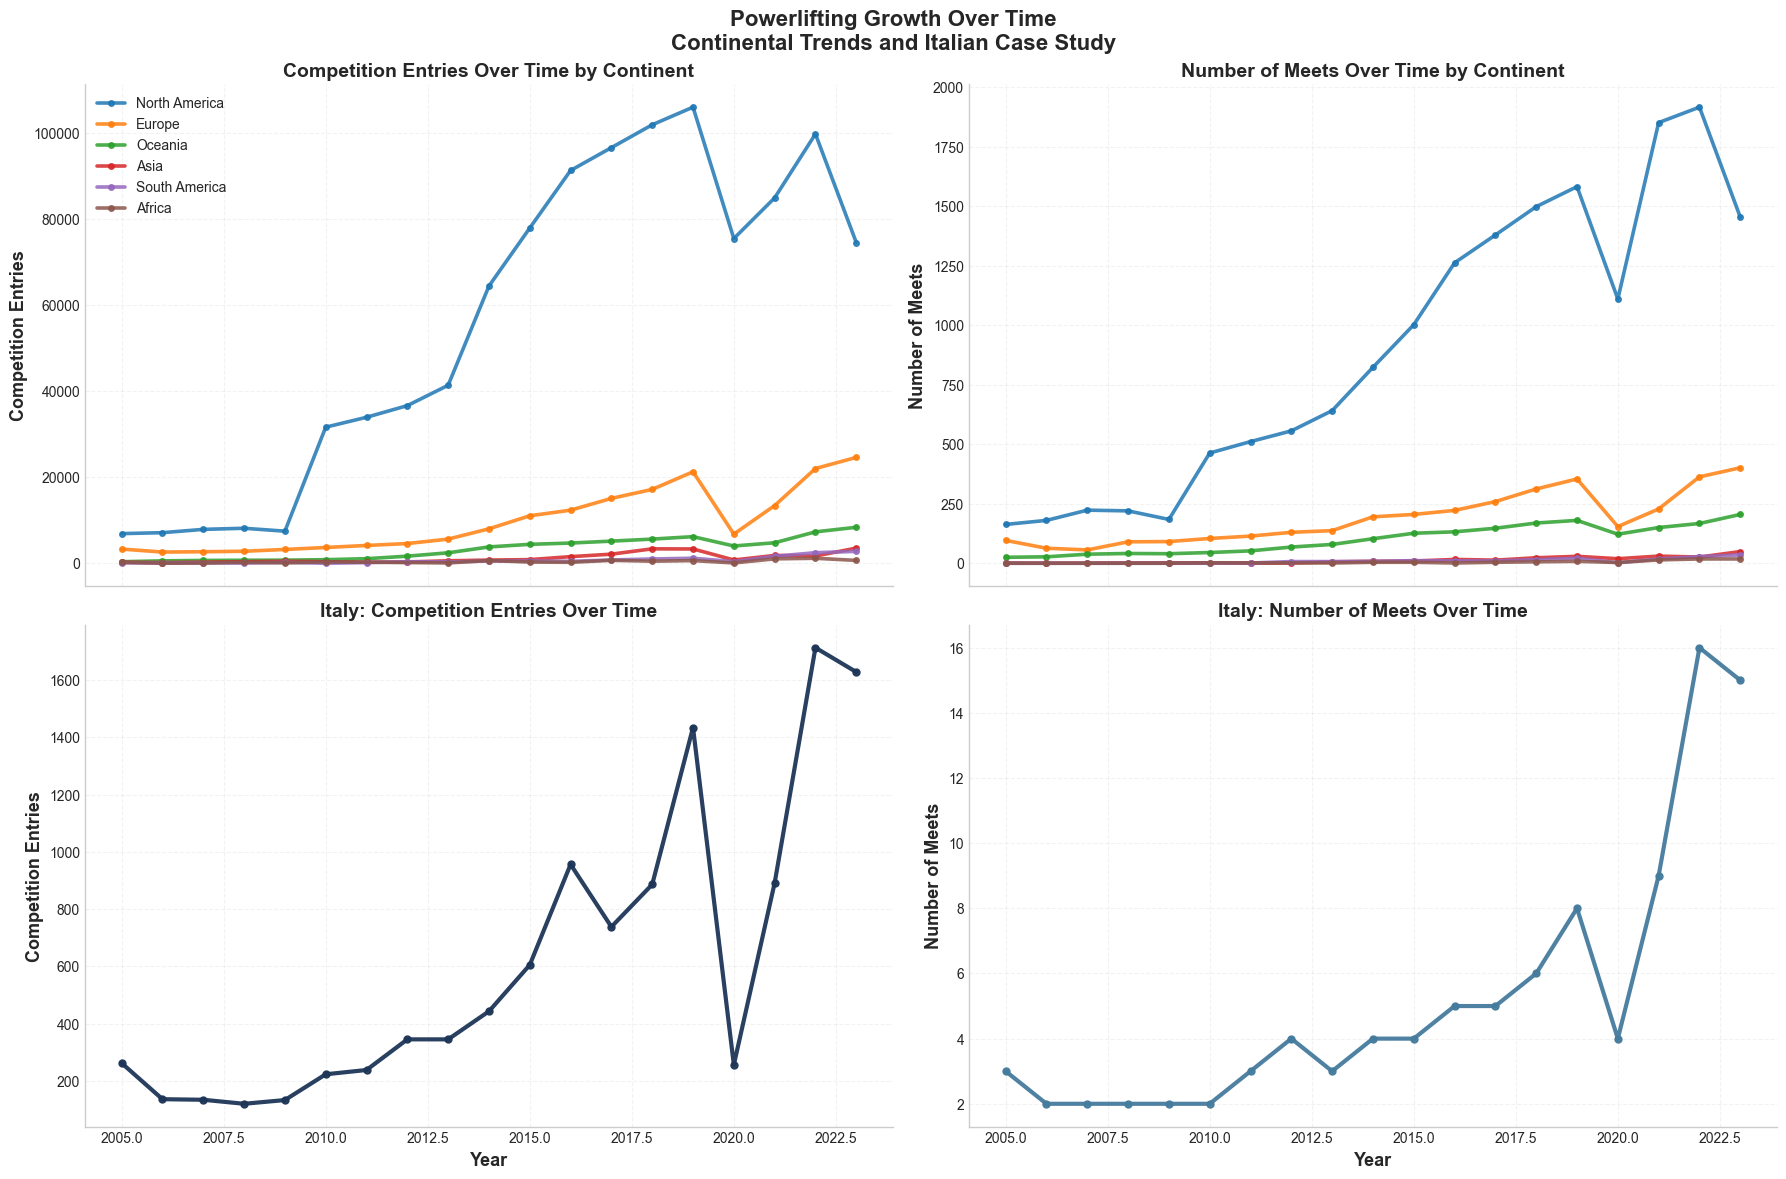

Regional growth (continent-level + Italy) saved!


In [88]:
# ----------------------------
# Country → Continent mapping
# ----------------------------
continent_map = {
    # Europe
    'Italy': 'Europe', 'France': 'Europe', 'Germany': 'Europe',
    'Spain': 'Europe', 'United Kingdom': 'Europe', 'UK': 'Europe',
    'Poland': 'Europe', 'Sweden': 'Europe', 'Norway': 'Europe',
    'Finland': 'Europe', 'Netherlands': 'Europe', 'Belgium': 'Europe',
    'Austria': 'Europe', 'Switzerland': 'Europe', 'Czech Republic': 'Europe',
    'Denmark': 'Europe', 'Ireland': 'Europe', 'Portugal': 'Europe',
    'Romania': 'Europe', 'Hungary': 'Europe',

    # North America
    'USA': 'North America', 'United States': 'North America',
    'Canada': 'North America', 'Mexico': 'North America',

    # South America
    'Brazil': 'South America', 'Argentina': 'South America',
    'Chile': 'South America', 'Colombia': 'South America',

    # Asia
    'Japan': 'Asia', 'China': 'Asia', 'South Korea': 'Asia',
    'India': 'Asia', 'Thailand': 'Asia', 'Philippines': 'Asia',

    # Oceania
    'Australia': 'Oceania', 'New Zealand': 'Oceania',

    # Africa
    'South Africa': 'Africa', 'Egypt': 'Africa', 'Morocco': 'Africa'
}


required_cols = {'MeetCountry', 'Year', 'MeetName', 'Name'}

if required_cols.issubset(df_clean.columns):

    df_region = df_clean.copy()

    # ----------------------------
    # Map continent
    # ----------------------------
    df_region['Continent'] = df_region['MeetCountry'].map(continent_map)
    df_region = df_region[df_region['Continent'].notna()]

    # ----------------------------
    # Aggregate by year + continent
    # ----------------------------
    yearly_continent = (
        df_region
        .groupby(['Year', 'Continent'])
        .agg(
            entries=('Name', 'count'),
            meets=('MeetName', 'nunique')
        )
        .reset_index()
    )

    # Order continents by total entries
    continent_order = (
        yearly_continent
        .groupby('Continent')['entries']
        .sum()
        .sort_values(ascending=False)
        .index
    )

    # ----------------------------
    # Figure layout
    # ----------------------------
    fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True)

    # ============================
    # CONTINENTS – ENTRIES
    # ============================
    ax1 = axes[0, 0]

    for continent in continent_order:
        data = yearly_continent[yearly_continent['Continent'] == continent]
        ax1.plot(
            data['Year'],
            data['entries'],
            linewidth=2.6,
            marker='o',
            markersize=4,
            alpha=0.85,
            label=continent
        )

    ax1.set_title('Competition Entries Over Time by Continent',
                  fontsize=14, fontweight='700')
    ax1.set_ylabel('Competition Entries',
                   fontsize=13, fontweight='600')

    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.grid(alpha=0.25, linestyle='--', linewidth=0.8)
    ax1.legend(frameon=False, fontsize=10)

    # ============================
    # CONTINENTS – MEETS
    # ============================
    ax2 = axes[0, 1]

    for continent in continent_order:
        data = yearly_continent[yearly_continent['Continent'] == continent]
        ax2.plot(
            data['Year'],
            data['meets'],
            linewidth=2.6,
            marker='o',
            markersize=4,
            alpha=0.85,
            label=continent
        )

    ax2.set_title('Number of Meets Over Time by Continent',
                  fontsize=14, fontweight='700')
    ax2.set_ylabel('Number of Meets',
                   fontsize=13, fontweight='600')

    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.grid(alpha=0.25, linestyle='--', linewidth=0.8)

    # ============================
    # ITALY – ENTRIES
    # ============================
    ax3 = axes[1, 0]

    italy_data = df_region[
        df_region['MeetCountry'].str.upper().isin(['ITALY', 'ITA'])
    ].groupby('Year').agg(
        entries=('Name', 'count'),
        meets=('MeetName', 'nunique')
    ).reset_index()

    ax3.plot(
        italy_data['Year'],
        italy_data['entries'],
        linewidth=3.0,
        marker='o',
        markersize=5,
        color='#1D3557',
        alpha=0.95
    )

    ax3.set_title('Italy: Competition Entries Over Time',
                  fontsize=14, fontweight='700')
    ax3.set_xlabel('Year',
                   fontsize=13, fontweight='600')
    ax3.set_ylabel('Competition Entries',
                   fontsize=13, fontweight='600')

    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.grid(alpha=0.25, linestyle='--', linewidth=0.8)

    # ============================
    # ITALY – MEETS
    # ============================
    ax4 = axes[1, 1]

    ax4.plot(
        italy_data['Year'],
        italy_data['meets'],
        linewidth=3.0,
        marker='o',
        markersize=5,
        color='#457B9D',
        alpha=0.95
    )

    ax4.set_title('Italy: Number of Meets Over Time',
                  fontsize=14, fontweight='700')
    ax4.set_xlabel('Year',
                   fontsize=13, fontweight='600')
    ax4.set_ylabel('Number of Meets',
                   fontsize=13, fontweight='600')

    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.grid(alpha=0.25, linestyle='--', linewidth=0.8)

    # ----------------------------
    # Final layout
    # ----------------------------
    plt.suptitle(
        'Powerlifting Growth Over Time\n'
        'Continental Trends and Italian Case Study',
        fontsize=16,
        fontweight='700',
        y=0.98
    )

    plt.tight_layout()
    plt.savefig(
        '../viz/viz6_regional_growth.png',
        dpi=300,
        bbox_inches='tight',
        facecolor='white'
    )
    plt.show()

    print("Regional growth (continent-level + Italy) saved!")

else:
    print("Warning: Required columns not found in dataset")


MOST COMMONLY MISSED ATTEMPTS

Failure rates by attempt:
   attempt  total_attempts  failures  failure_rate_pct
   Bench 3          225912    116058         51.373101
Deadlift 3          224696     78660         35.007299
   Squat 3          225826     70903         31.397182
   Bench 2          228547     40118         17.553501
   Squat 2          228268     32044         14.037885
   Squat 1          229105     23390         10.209293
Deadlift 2          227781     22566          9.906884
   Bench 1          229083     15623          6.819799
Deadlift 1          229116      8184          3.571990


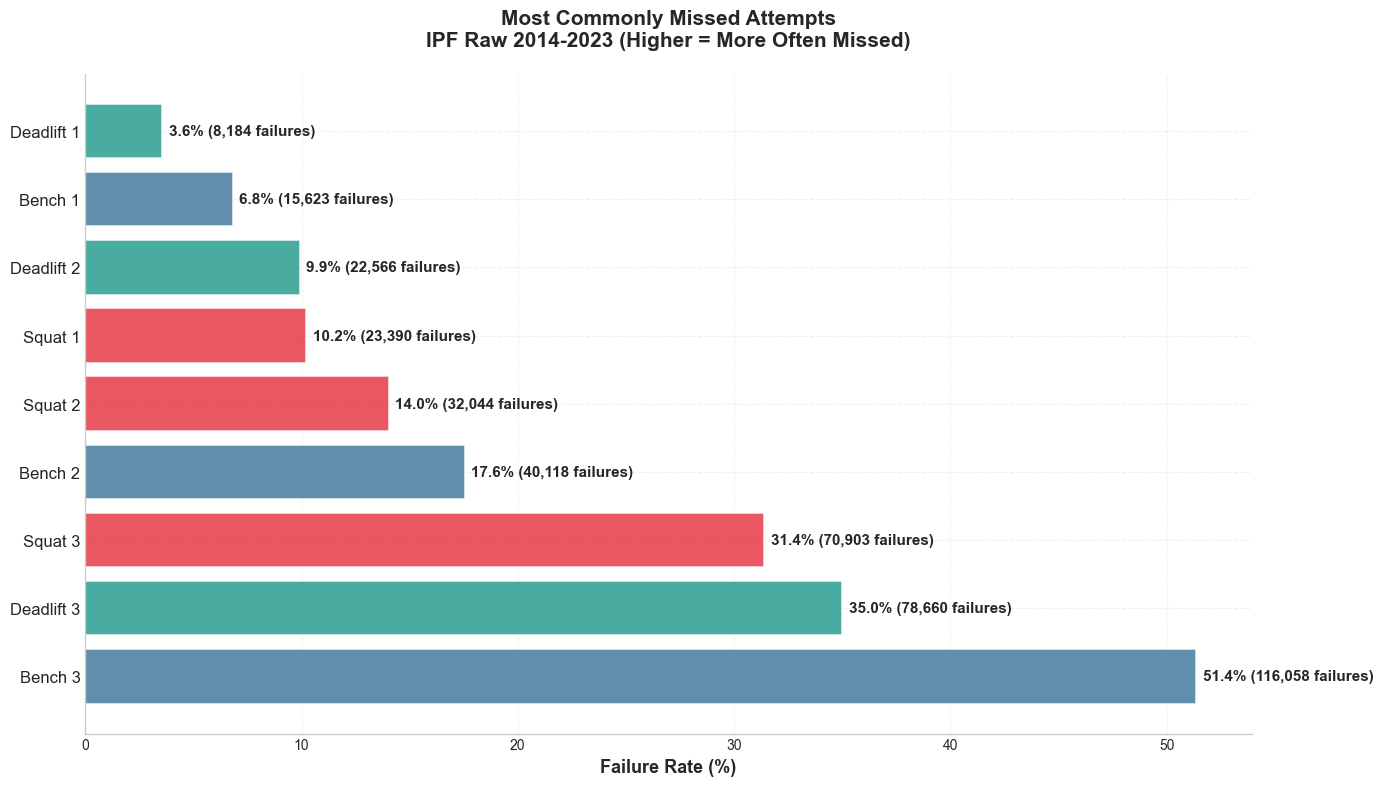


⚠ Most commonly missed attempt: Bench 3 (51.4% failure rate)
This contradicts the 'YOLO deadlift' assumption - bench attempts fail more often!


In [96]:
# ============================================================================
# MOST COMMONLY MISSED LIFTS
# ============================================================================

print("\n" + "=" * 80)
print("MOST COMMONLY MISSED ATTEMPTS")
print("=" * 80)

# Count failures for each attempt
attempt_columns = [
    ('Squat1Kg', 'Squat 1'),
    ('Squat2Kg', 'Squat 2'),
    ('Squat3Kg', 'Squat 3'),
    ('Bench1Kg', 'Bench 1'),
    ('Bench2Kg', 'Bench 2'),
    ('Bench3Kg', 'Bench 3'),
    ('Deadlift1Kg', 'Deadlift 1'),
    ('Deadlift2Kg', 'Deadlift 2'),
    ('Deadlift3Kg', 'Deadlift 3')
]

miss_data = []

for col, label in attempt_columns:
    if col in df_success.columns:
        # Count total attempts (where value is not NaN)
        total_attempts = df_success[col].notna().sum()
        
        # Count failures (negative values or zero)
        failures = ((df_success[col] <= 0) & df_success[col].notna()).sum()
        
        # Calculate failure rate
        if total_attempts > 0:
            failure_rate = (failures / total_attempts) * 100
            miss_data.append({
                'attempt': label,
                'total_attempts': total_attempts,
                'failures': failures,
                'failure_rate_pct': failure_rate
            })

miss_df = pd.DataFrame(miss_data)
miss_df = miss_df.sort_values('failure_rate_pct', ascending=False)

print("\nFailure rates by attempt:")
print(miss_df.to_string(index=False))

# ============================================================================
# VISUALIZATION 2: MOST COMMONLY MISSED LIFTS
# ============================================================================

fig, ax = plt.subplots(figsize=(14, 8))

# Color by lift type
lift_colors_map = {
    'Squat': '#E63946',
    'Bench': '#457B9D',
    'Deadlift': '#2A9D8F'
}

colors_bars = [lift_colors_map[attempt.split()[0]] for attempt in miss_df['attempt']]

bars = ax.barh(
    range(len(miss_df)),
    miss_df['failure_rate_pct'],
    color=colors_bars,
    edgecolor='white',
    linewidth=1.2,
    alpha=0.85
)

# Add percentage labels
for idx, (i, row) in enumerate(miss_df.iterrows()):
    ax.text(
        row['failure_rate_pct'] + 0.3,
        idx,
        f"{row['failure_rate_pct']:.1f}% ({int(row['failures']):,} failures)",
        va='center',
        fontsize=11,
        fontweight='600'
    )

ax.set_yticks(range(len(miss_df)))
ax.set_yticklabels(miss_df['attempt'], fontsize=12)
ax.set_xlabel('Failure Rate (%)', fontsize=13, fontweight='600')
ax.set_title('Most Commonly Missed Attempts\nIPF Raw 2014-2023 (Higher = More Often Missed)', 
             fontsize=15, fontweight='700', pad=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig('../viz/viz7_most_missed_attempts.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

most_missed = miss_df.iloc[0]
print(f"\n⚠ Most commonly missed attempt: {most_missed['attempt']} ({most_missed['failure_rate_pct']:.1f}% failure rate)")
print(f"This contradicts the 'YOLO deadlift' assumption - bench attempts fail more often!")


WIN RATE BY SUCCESSFUL ATTEMPTS
 successful_attempts  total_lifters  winners  win_rate_pct
                   9          38114    17209     45.151388
                   8          64089    27372     42.709357
                   7          60071    24489     40.766759
                   6          39768    15302     38.478173
                   5          19165     7058     36.827550
                   4           6377     2235     35.047828
                   3           1505      572     38.006645
                   2             48       28     58.333333
                   1              1        0      0.000000


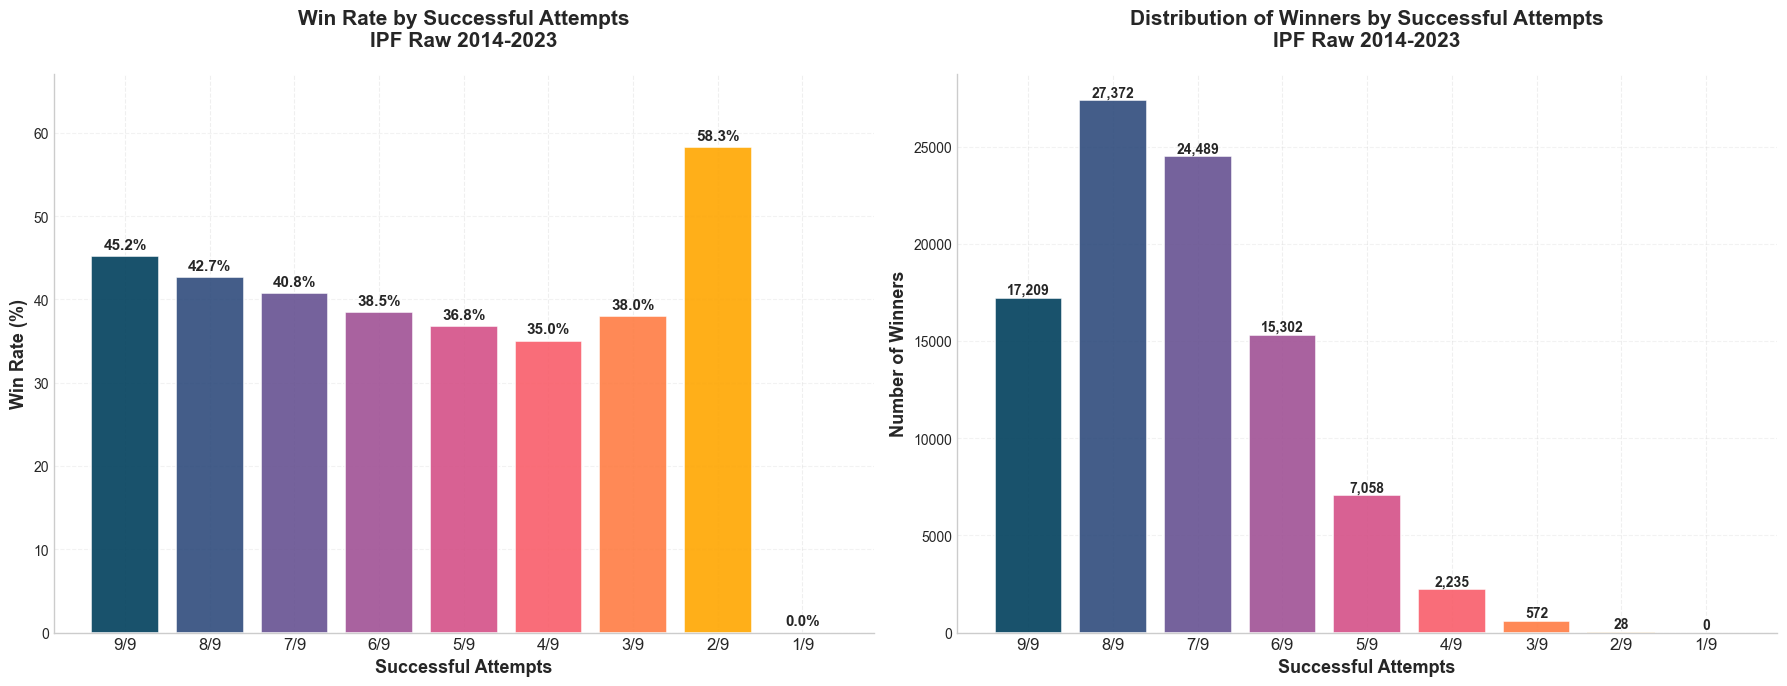


Key Insight:
Going 9/9 gives you a 45.2% chance of winning
Going 8/9 gives you a 42.7% chance of winning
Improvement from 8/9 to 9/9: +2.4 percentage points
Improvement from 7/9 to 9/9: +4.4 percentage points


In [94]:
# ============================================================================
# WIN RATE BY SUCCESSFUL ATTEMPTS
# ============================================================================

# Calculate win rate for each success level
win_rate_data = df_success.groupby('successful_attempts').agg(
    total_lifters=('Name', 'count'),
    winners=('is_winner', 'sum')
).reset_index()

win_rate_data['win_rate_pct'] = (win_rate_data['winners'] / win_rate_data['total_lifters']) * 100

# Sort by successful attempts (descending)
win_rate_data = win_rate_data.sort_values('successful_attempts', ascending=False)

print("\n" + "=" * 80)
print("WIN RATE BY SUCCESSFUL ATTEMPTS")
print("=" * 80)
print(win_rate_data.to_string(index=False))
print("=" * 80)

# ============================================================================
# VISUALIZATION 1: WIN RATE CHART
# ============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# --- Left: Win Rate Percentage ---
colors_gradient = ['#003f5c', '#2f4b7c', '#665191', '#a05195', '#d45087', 
                   '#f95d6a', '#ff7c43', '#ffa600', '#ffd700', '#ffed4e']

# Reverse to match article style (9/9 first)
x_positions = range(len(win_rate_data))
bars1 = ax1.bar(
    x_positions,
    win_rate_data['win_rate_pct'],
    color=colors_gradient[:len(win_rate_data)],
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9
)

# Add percentage labels on bars
for idx, (i, row) in enumerate(win_rate_data.iterrows()):
    ax1.text(
        idx,
        row['win_rate_pct'] + 0.5,
        f"{row['win_rate_pct']:.1f}%",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='600'
    )

ax1.set_xticks(x_positions)
ax1.set_xticklabels([f"{int(x)}/9" for x in win_rate_data['successful_attempts']], fontsize=12)
ax1.set_xlabel('Successful Attempts', fontsize=13, fontweight='600')
ax1.set_ylabel('Win Rate (%)', fontsize=13, fontweight='600')
ax1.set_title('Win Rate by Successful Attempts\nIPF Raw 2014-2023', 
              fontsize=15, fontweight='700', pad=20)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)
ax1.set_ylim(0, max(win_rate_data['win_rate_pct']) * 1.15)

# --- Right: Number of Winners ---
bars2 = ax2.bar(
    x_positions,
    win_rate_data['winners'],
    color=colors_gradient[:len(win_rate_data)],
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9
)

# Add count labels on bars
for idx, (i, row) in enumerate(win_rate_data.iterrows()):
    ax2.text(
        idx,
        row['winners'] + 50,
        f"{int(row['winners']):,}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='600'
    )

ax2.set_xticks(x_positions)
ax2.set_xticklabels([f"{int(x)}/9" for x in win_rate_data['successful_attempts']], fontsize=12)
ax2.set_xlabel('Successful Attempts', fontsize=13, fontweight='600')
ax2.set_ylabel('Number of Winners', fontsize=13, fontweight='600')
ax2.set_title('Distribution of Winners by Successful Attempts\nIPF Raw 2014-2023', 
              fontsize=15, fontweight='700', pad=20)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', alpha=0.25, linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig('../viz/viz7_win_rate_by_attempts.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("\nKey Insight:")
if len(win_rate_data[win_rate_data['successful_attempts'] == 9]) > 0:
    win_9_9 = win_rate_data[win_rate_data['successful_attempts'] == 9]['win_rate_pct'].values[0]
    win_8_9 = win_rate_data[win_rate_data['successful_attempts'] == 8]['win_rate_pct'].values[0]
    win_7_9 = win_rate_data[win_rate_data['successful_attempts'] == 7]['win_rate_pct'].values[0]

    print(f"Going 9/9 gives you a {win_9_9:.1f}% chance of winning")
    print(f"Going 8/9 gives you a {win_8_9:.1f}% chance of winning")
    print(f"Improvement from 8/9 to 9/9: +{(win_9_9 - win_8_9):.1f} percentage points")
    print(f"Improvement from 7/9 to 9/9: +{(win_9_9 - win_7_9):.1f} percentage points")


MOST COMMONLY MISSED ATTEMPTS

Failure rates by attempt:
   attempt  total_attempts  failures  failure_rate_pct
   Bench 3          225912    116058         51.373101
Deadlift 3          224696     78660         35.007299
   Squat 3          225826     70903         31.397182
   Bench 2          228547     40118         17.553501
   Squat 2          228268     32044         14.037885
   Squat 1          229105     23390         10.209293
Deadlift 2          227781     22566          9.906884
   Bench 1          229083     15623          6.819799
Deadlift 1          229116      8184          3.571990


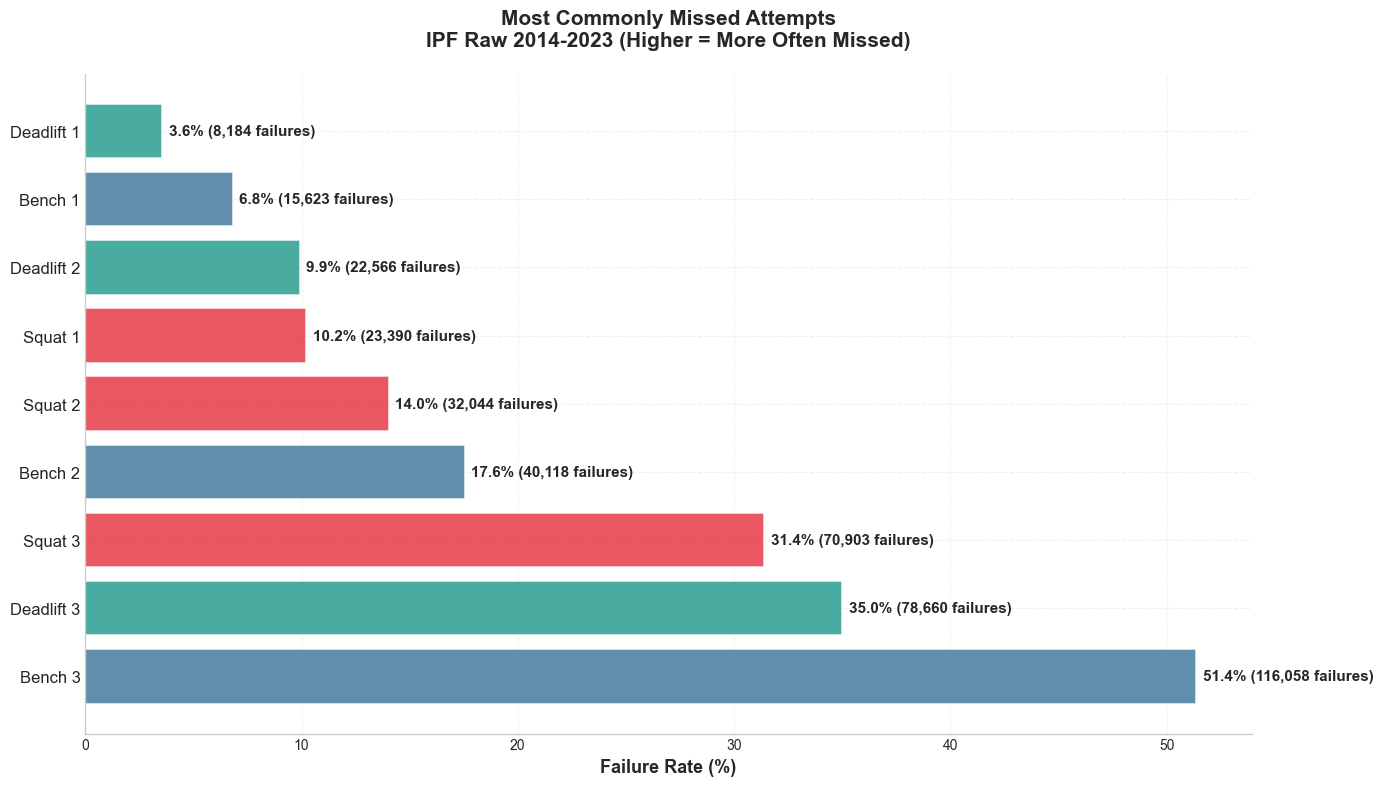


Most commonly missed attempt: Bench 3 (51.4% failure rate)
This contradicts the 'YOLO deadlift' assumption - bench attempts fail more often!


In [93]:
# ============================================================================
# MOST COMMONLY MISSED LIFTS
# ============================================================================

print("\n" + "=" * 80)
print("MOST COMMONLY MISSED ATTEMPTS")
print("=" * 80)

# Count failures for each attempt
attempt_columns = [
    ('Squat1Kg', 'Squat 1'),
    ('Squat2Kg', 'Squat 2'),
    ('Squat3Kg', 'Squat 3'),
    ('Bench1Kg', 'Bench 1'),
    ('Bench2Kg', 'Bench 2'),
    ('Bench3Kg', 'Bench 3'),
    ('Deadlift1Kg', 'Deadlift 1'),
    ('Deadlift2Kg', 'Deadlift 2'),
    ('Deadlift3Kg', 'Deadlift 3')
]

miss_data = []

for col, label in attempt_columns:
    if col in df_success.columns:
        # Count total attempts (where value is not NaN)
        total_attempts = df_success[col].notna().sum()
        
        # Count failures (negative values or zero)
        failures = ((df_success[col] <= 0) & df_success[col].notna()).sum()
        
        # Calculate failure rate
        if total_attempts > 0:
            failure_rate = (failures / total_attempts) * 100
            miss_data.append({
                'attempt': label,
                'total_attempts': total_attempts,
                'failures': failures,
                'failure_rate_pct': failure_rate
            })

miss_df = pd.DataFrame(miss_data)
miss_df = miss_df.sort_values('failure_rate_pct', ascending=False)

print("\nFailure rates by attempt:")
print(miss_df.to_string(index=False))

# ============================================================================
# VISUALIZATION 2: MOST COMMONLY MISSED LIFTS
# ============================================================================

fig, ax = plt.subplots(figsize=(14, 8))

# Color by lift type
lift_colors_map = {
    'Squat': '#E63946',
    'Bench': '#457B9D',
    'Deadlift': '#2A9D8F'
}

colors_bars = [lift_colors_map[attempt.split()[0]] for attempt in miss_df['attempt']]

bars = ax.barh(
    range(len(miss_df)),
    miss_df['failure_rate_pct'],
    color=colors_bars,
    edgecolor='white',
    linewidth=1.2,
    alpha=0.85
)

# Add percentage labels
for idx, (i, row) in enumerate(miss_df.iterrows()):
    ax.text(
        row['failure_rate_pct'] + 0.3,
        idx,
        f"{row['failure_rate_pct']:.1f}% ({int(row['failures']):,} failures)",
        va='center',
        fontsize=11,
        fontweight='600'
    )

ax.set_yticks(range(len(miss_df)))
ax.set_yticklabels(miss_df['attempt'], fontsize=12)
ax.set_xlabel('Failure Rate (%)', fontsize=13, fontweight='600')
ax.set_title('Most Commonly Missed Attempts\nIPF Raw 2014-2023 (Higher = More Often Missed)', 
             fontsize=15, fontweight='700', pad=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.25, linestyle='--', linewidth=0.8)


plt.tight_layout()
plt.savefig('../data/viz7_most_missed_attempts.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

most_missed = miss_df.iloc[0]
print(f"\nMost commonly missed attempt: {most_missed['attempt']} ({most_missed['failure_rate_pct']:.1f}% failure rate)")
print(f"This contradicts the 'YOLO deadlift' assumption - bench attempts fail more often!")

In [92]:
# ============================================================================
# CALCULATE SUCCESSFUL ATTEMPTS FOR EACH LIFTER
# ============================================================================
# Filter for IPF Raw 2014-2023 (same as the article)

print("=" * 80)
print("SUCCESS RATE ANALYSIS - IPF RAW 2014-2023")
print("=" * 80)

df_success = df_clean.copy()

# Apply IPF filters
if 'Equipment' in df_success.columns:
    df_success = df_success[df_success['Equipment'] == 'Raw'].copy()

if 'Federation' in df_success.columns:
    ipf_feds = ['IPF', 'USAPL', 'CPU', 'BP', 'EPA', 'IrishPF', 'PA', 'CAPO']
    df_success = df_success[df_success['Federation'].isin(ipf_feds)].copy()

if 'Year' in df_success.columns:
    df_success = df_success[(df_success['Year'] >= 2014) & (df_success['Year'] <= 2023)].copy()

print(f"Filtered dataset: {len(df_success):,} rows")

# ============================================================================
# Calculate successful attempts
# A lift is considered successful if the value is positive (negative = failed)
# ============================================================================

def count_successful_attempts(row):
    """Count how many of the 9 attempts (3 squat, 3 bench, 3 deadlift) were successful"""
    successful = 0
    
    # Squat attempts
    for col in ['Squat1Kg', 'Squat2Kg', 'Squat3Kg']:
        if pd.notna(row[col]) and row[col] > 0:
            successful += 1
    
    # Bench attempts
    for col in ['Bench1Kg', 'Bench2Kg', 'Bench3Kg']:
        if pd.notna(row[col]) and row[col] > 0:
            successful += 1
    
    # Deadlift attempts
    for col in ['Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg']:
        if pd.notna(row[col]) and row[col] > 0:
            successful += 1
    
    return successful

# Count successful attempts for each lifter
df_success['successful_attempts'] = df_success.apply(count_successful_attempts, axis=1)

# ============================================================================
# IMPORTANT FIX: Filter out invalid data
# ============================================================================
# Remove entries where:
# 1. They have 0 successful attempts (impossible to compete)
# 2. They don't have a valid total (indicates disqualification or incomplete data)

print(f"\nBefore filtering invalid data: {len(df_success):,} rows")

# Filter out 0 successful attempts
df_success = df_success[df_success['successful_attempts'] > 0].copy()
print(f"After removing 0 successful attempts: {len(df_success):,} rows")

# Filter for valid Place values (numeric or '1', '2', '3', etc. - not 'DQ', 'DD', 'NS')
# Keep only entries where Place is a number or looks like a placement
df_success = df_success[df_success['Place'].notna()].copy()
df_success = df_success[~df_success['Place'].str.upper().isin(['DQ', 'DD', 'NS', 'G'])].copy()
print(f"After removing DQ/NS entries: {len(df_success):,} rows")

# Determine if the lifter won (Place == '1')
df_success['is_winner'] = df_success['Place'] == '1'

print(f"\nSuccessful attempts distribution:")
print(df_success['successful_attempts'].value_counts().sort_index(ascending=False))
print(f"\nTotal winners: {df_success['is_winner'].sum():,}")

# Debug: Check if we still have any winners with very few successful attempts
debug_low_attempts = df_success[(df_success['is_winner']) & (df_success['successful_attempts'] < 6)]
if len(debug_low_attempts) > 0:
    print(f"\n⚠ WARNING: Found {len(debug_low_attempts)} winners with <6 successful attempts")
    print("Sample of these entries:")
    print(debug_low_attempts[['Name', 'successful_attempts', 'Place', 'TotalKg', 'WeightClass']].head(10))

SUCCESS RATE ANALYSIS - IPF RAW 2014-2023
Filtered dataset: 256,905 rows

Before filtering invalid data: 256,905 rows
After removing 0 successful attempts: 231,284 rows
After removing DQ/NS entries: 229,138 rows

Successful attempts distribution:
successful_attempts
9    38114
8    64089
7    60071
6    39768
5    19165
4     6377
3     1505
2       48
1        1
Name: count, dtype: int64

Total winners: 94,265

⚠ WARNING: Found 9893 winners with <6 successful attempts
Sample of these entries:
                     Name  successful_attempts Place  TotalKg WeightClass
109194    Thomas Celestin                    5     1    650.0        93kg
109238      Arthur Cowley                    5     1    550.0       105kg
109240       Ernie Parkes                    4     1    407.5        74kg
109243        Aftab Uddin                    4     1    517.5        59kg
109295  Aaron Thompson #1                    5     1    895.0      120kg+
109388        Nash Hunter                    5     1    4

## 10. Visualization 7: Success Rate and Winning Probability

**Question:** Are lifters who go 9-for-9 (making all attempts) more likely to win? Which attempts are most commonly missed?

Inspired by: [Powerlifting in Data - Lifters Going 9-for-9 Are More Likely to Win](https://powerliftingindata.com/posts/2024/11/03/lifters-going-9-for-9-are-more-likely-to-win.html)